# Process 10x satseq data

Demonstates how we ran cellranger, and also used barcode-variant map from pacbio to label variants in 10x data

Produces filtered 10x data set (.h5ad file) with variants labelled

This particular notebook for 4T1 tumor data in Laughney-MD-16637_2024_06_11/4T1

Other satseq 10x datasets were processed in the same way. Except in this case, we chose to remove one of the samples (4T1_4) due to quality issues. For other data sets, we kept all samples.

In [1]:
import gzip
import multiprocessing
import os
import sys
import time
from importlib.metadata import version

import editdistance
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from kneed import KneeLocator
from scipy.sparse import coo_matrix, csr_matrix

In [2]:
print(f"Python: {sys.version.split()[0]}")

packages = [
    "editdistance",
    "h5py",
    "matplotlib",
    "numpy",
    "pandas",
    "scanpy",
    "kneed",
    "scipy"
]

for package in packages:
    print(f"{package}: {version(package)}")

Python: 3.10.12
editdistance: 0.8.1
h5py: 3.10.0
matplotlib: 3.8.3
numpy: 1.26.4
pandas: 2.2.1
scanpy: 1.9.8
kneed: 0.8.5
scipy: 1.12.0


In [3]:
sys.path.append('python')

import scrna_processing as scrpr

In [4]:
# This pipeline requires mmseqs for aligning pacbio and 10x barcodes

# If you have it installed already, set path to it here:
mmseqs_executable='/opt/mmseqs/bin/mmseqs'

# Or, you can install the latest version with (uncomment and run)
# ! mkdir -p /opt
# cd /opt && wget https://dev.mmseqs.com/latest/mmseqs-linux-avx2.tar.gz && tar -zxf mmseqs-linux-av2.tar.gz
# mmseqs_executable='/opt/mmseqs/bin/mmseqs'

# The mmseqs version used here is 8ef870f95af2a3ee474c2cdbb845f5f007fe5be6, which was the lastet version as of Feb 10, 2025.
# This version can be installed with:
# !mkdir -p /opt
# ! cd /opt && git clone https://github.com/soedinglab/MMseqs2.git && cd MMseqs2 && git checkout 8ef870f95af2a3ee474c2cdbb845f5f007fe5be6 && mkdir build
# ! cd /opt/MMseqs2/build && cmake -DCMAKE_BUILD_TYPE=RELEASE -DCMAKE_INSTALL_PREFIX=. .. && make -j && make install
# mmseqs_executable='/opt/MMseqs2/build/bin/mmseqs'


In [5]:
print(mmseqs_executable)
!{mmseqs_executable} version

/opt/mmseqs/bin/mmseqs
8ef870f95af2a3ee474c2cdbb845f5f007fe5be6


In [6]:
output_dir='/workdir/satseq/10x_processing'
print(output_dir)

/workdir/satseq/10x_processing


In [7]:
!mkdir -p {output_dir}

In [8]:
celltype='4T1'
# celltype = 'EO771'
condition='tumor'
#condition='cGAMP'
#condition = 'H2O'

In [9]:
print(f'celltype={celltype} condition={condition}')

celltype=4T1 condition=tumor


In [10]:
# Set this to the directory containing cellranger output
cellranger_out_dir=''
if condition == 'tumor':
    cellranger_out_dir=f'/workdir/satseq/Laughney-MD-16637_2024_06_11/{celltype}'
    samples = [f'{celltype}_{i+1}' for i in range(8)]
elif condition=='cGAMP' or condition=='H2O':
    cellranger_out_dir=f'/workdir/satseq/Laughney-AO-17382-2024_10_22/{celltype}'
    samples = [f'{celltype}_{condition}_{i+1}' for i in range(4)]
if cellranger_out_dir=='':
    print('error: Invalid celltype/condition')
print(f'cellranger_out_dir={cellranger_out_dir}')
print('samples: ' + ' '.join(samples))

cellranger_out_dir=/workdir/satseq/Laughney-MD-16637_2024_06_11/4T1
samples: 4T1_1 4T1_2 4T1_3 4T1_4 4T1_5 4T1_6 4T1_7 4T1_8


## Step 0a: Run cellranger with twist variant map

This was done outside the notebook, on command line

In [11]:
!cat bash/run_cellranger.sh

#!/bin/bash

# This is for 4T1 and EO771.lmb, samples, other satseq 10x samples were processed similarly

export PATH=/workdir/mt269/cellranger-8.0.1/bin:$PATH


# Point to 10x reference sequence
refpath=/workdir/refdata-gex-mm10-2020-A

# Point to description of barcodes for each variant
# Note: for the paper we used the v2 file, but it had some minor errors
# that were corrected downstream. The errors are fixed in the v3 file,
# we recommend using that going forward
# featureFile=../data/twist_mSTING_full_feature_ref_v2.csv
featureFile=../data/twist_mSTING_full_feature_ref_v3.csv

## in this case we had directory structure like:
## 4T1/transcripts/*.fastq.gz:        fastqs from RNA for 8 4T1 samples
## 4T1/feature_barcodes/*.fastq.gz:   fastqs from satseq barcode reads for 4T1 samples
## E0771/transcripts/*.fastq.gz:      fastqs from RNA for 8 EO771.lmb samples
## EO771/feature_barcodes/*.fastq.gz: fastqs from satseq barcode reads for the EO771.lmb samples

# The fastq files in each 

## Step 0b: Get consensus barcode for each cell

The pipeline below was also run on the command-line for each sample. It gets the assignments of barcode reads to cells from the cellranger output, aligns the barcodes to a reference template, and then
uses `samtools consensus` to get a consensus barcode per cell. The code is in bash/bowtie_pileup.sh, and the first argument would be {cellranger_out_dir}/{sample}/outs/possorted_genome_bam.bam

In [12]:
!cat bash/bowtie_pileup.sh

#!/bin/bash

## Get the feature barcode associated with each cell. Uses cellranger bam output and a barcode reference

# adds two files to the cellranger 'outs' dir:
# -- barcode_align.bam: an alignment of R2 reads to a barcode template. Maps all reads that are assigned a
#        cell barcode by cellranger
#    Note: I have tried only mapping reads that have flag=4 (i.e., removing ones marked as 'PCR duplicate').
#        But, we seem to lose a significant fraction of mappings this way
# -- barcode_consensus_simple.fa.gz: A fasta file where sequence name is cell name, and sequence is the
#        'consensus' R2 sequence after all reads are mapped to barcode template.
#        The actual barcode should be found in this sequence in positions 20:56 (zero-based).
#    Note: I have tried calling consensus without --mode=simple, it produced fewer overall mappings. But
#        with the output bam file, samtools consensus can be re-run easily with different parameters, if desired.


bamfile=

## Read in data

In [13]:
adatas = [sc.read_10x_h5(cellranger_out_dir + '/' + s + '/outs/raw_feature_bc_matrix.h5', gex_only=False) for s in samples]

/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_name

In [14]:
for i,s in enumerate(samples):
    adatas[i].obs['sample'] = s
    adatas[i].obs['sample'] = adatas[i].obs['sample'].astype(str)
    adatas[i].obs.index = [f'{x}-{i}' for x in adatas[i].obs.index]

### Get read depth matrix from cellRanger output

In [15]:
for i,s in enumerate(samples):
    readData = h5py.File(cellranger_out_dir + '/' + s + '/outs/molecule_info.h5', 'r')
    read_matrix = csr_matrix((readData['count'], (readData['barcode_idx'], readData['feature_idx'])), shape=adatas[i].shape)

    #gene_ids should be unique
    gene_ids = adatas[i].var.gene_ids
    geneTable = gene_ids.value_counts()
    print(f"Num unique gene IDs: {sum(geneTable==1)}\nNum non-unique gene IDs: {sum(geneTable > 1)}")
    if sum(geneTable > 1) > 0:
        print("ERROR: Gene IDs not unique")
    gene_names = adatas[i].var.index
    geneTable = gene_names.value_counts()
    print(f"Num unique gene names: {sum(geneTable==1)}\nNum non-unique gene names: {sum(geneTable > 1)}")
    if sum(geneTable > 1) > 0:
        tdata = adatas[i].copy().T
        dupGenes = geneTable[geneTable > 1].index
        #print(f"Duplicated gene [indices]")
        removeGenes = np.zeros(len(gene_names), bool)
        for dupGene in dupGenes:
            idx = [i for i in range(len(gene_names)) if gene_names[i] == dupGene] 
            #print(dupGene,idx)
            for j in range(len(idx)):
                if (j != 0):
                    tdata.X[idx[0],:] += tdata.X[idx[j],:]
                    read_matrix[:,idx[0]] += read_matrix[:,idx[j]]
                    removeGenes[idx[j]] = True
        tdata = tdata[~removeGenes]
        adatas[i] = tdata.copy().T
        read_matrix = read_matrix[:,~removeGenes]
        print(f"Combined {len(dupGenes)} genes; removed {sum(removeGenes)} columns")
    adatas[i].layers['read_matrix'] = read_matrix

Num unique gene IDs: 32677
Num non-unique gene IDs: 0
Num unique gene names: 32599
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns
Num unique gene IDs: 32677
Num non-unique gene IDs: 0
Num unique gene names: 32599
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns
Num unique gene IDs: 32677
Num non-unique gene IDs: 0
Num unique gene names: 32599
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


... (7 outputs left out)

/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns
Num unique gene IDs: 32677
Num non-unique gene IDs: 0
Num unique gene names: 32599
Num non-unique gene names: 38


/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1908: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.10/dist-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)
/usr/local/lib/python3.10/dist-packages/scipy/sparse/_index.py:136: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Combined 38 genes; removed 40 columns


## Separate variant and genes in adatas

STING variants are stored in adata columns with `adata.var['feature_type'] == 'Custom'`, we don't want to treat these as genes, instead store these counts in `adata.obsm['variant_counts']` and `adata.obsm['variant_reads']`

In [16]:
genes = list(adatas[0].var.loc[adatas[0].var['feature_types'] == 'Gene Expression'].index)
variants = list(adatas[0].var.loc[adatas[0].var['feature_types'] == 'Custom'].index)

for i in range(len(adatas)):
    if sum(np.array(adatas[i].var.loc[adatas[0].var['feature_types'] == 'Gene Expression'].index) != np.array(genes)) != 0:
        print('error1')
    if sum(np.array(adatas[i].var.loc[adatas[0].var['feature_types'] == 'Custom'].index) != np.array(variants)) != 0:
        print('error2')
print(len(genes), len(variants))

32245 392


In [17]:
for i in range(len(adatas)):
    print(i, adatas[i].shape)
    adatas[i].obsm['variant_counts'] = adatas[i][:,variants].X
    adatas[i].obsm['variant_reads'] = adatas[i][:,variants].layers['read_matrix']
    adatas[i] = adatas[i][:,genes]
    print(i, adatas[i].shape)

0 (1689388, 32637)
0 (1689388, 32245)
1 (1463840, 32637)
1 (1463840, 32245)
2 (1989300, 32637)
2 (1989300, 32245)
3 (1536987, 32637)
3 (1536987, 32245)
4 (1518687, 32637)
4 (1518687, 32245)
5 (1388632, 32637)
5 (1388632, 32245)
6 (1353812, 32637)
6 (1353812, 32245)
7 (1406294, 32637)
7 (1406294, 32245)


In [18]:
for i in range(len(adatas)):
    for f in ['variant_counts', 'variant_reads']:
        adatas[i].obsm[f] = np.array(adatas[i].obsm[f].todense())

/tmp/ipykernel_4105/1318859062.py:3: ImplicitModificationWarning: Setting element `.obsm['variant_counts']` of view, initializing view as actual.
  adatas[i].obsm[f] = np.array(adatas[i].obsm[f].todense())


### Filter cells based on size

In [19]:
# calculate mtFrac and library_size first
for i,adata in enumerate(adatas):
    msum = np.array(adata.X.sum(axis=1)).flatten()
    mt_genes = [x for x in adata.var.index if x.startswith('mt')]
    mt = np.array(adata[:,mt_genes].X.sum(axis=1)).flatten()
    f = msum == 0
    adatas[i].obs['library_size'] = msum
    adatas[i].obs['mt_frac'] = 0.0
    adatas[i].obs.loc[adatas[i].obs['library_size'] > 0,'mt_frac'] = mt[~f]/msum[~f]

__First look at overview of sizes__

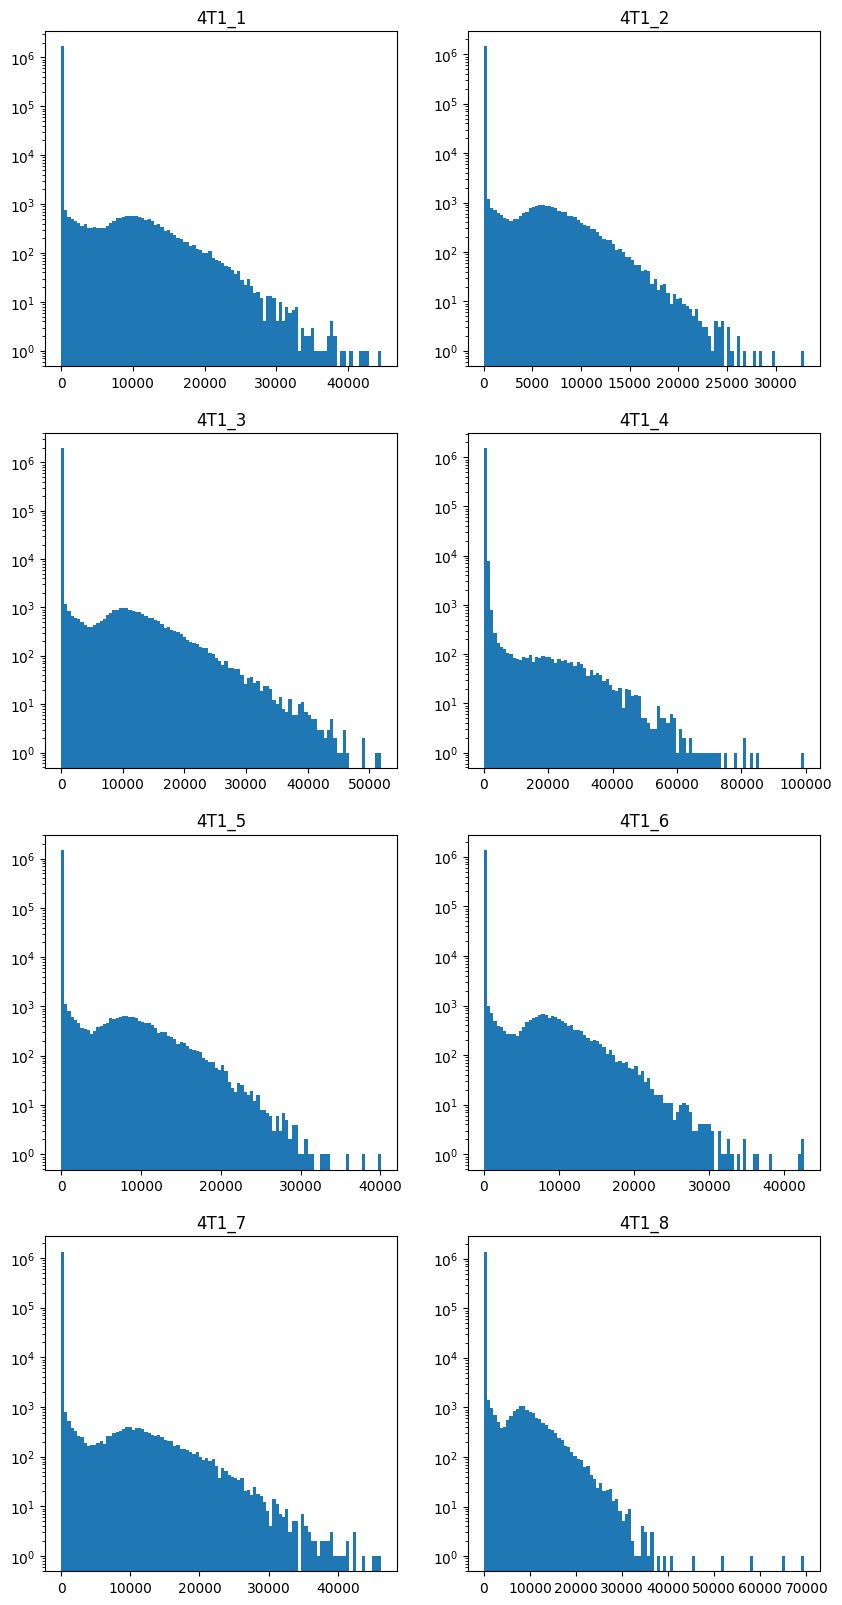

In [20]:
nrows=int(np.ceil(len(samples)/2))
ncols=2
plt.subplots(nrows=nrows,ncols=ncols,figsize=(ncols*5,nrows*5))
for i in range(len(adatas)):
    plt.subplot(nrows,ncols,i+1)
    vals = np.array(np.sum(adatas[i].X, axis=1)).flatten()
#    vals = vals[vals > 100]
    plt.hist(vals, bins=100)
    plt.yscale('log')
    #plt.axvline(np.log10(2000))
    plt.title(adatas[i].obs['sample'].iloc[0])
plt.show()

__Now zoom in on range from first to second peak. May need to adjust maxx and binsize below, want smallest binsize that results in relatively smooth plot and good choice of cutoff for all samples. Maybe stick with 200 if it looks good__

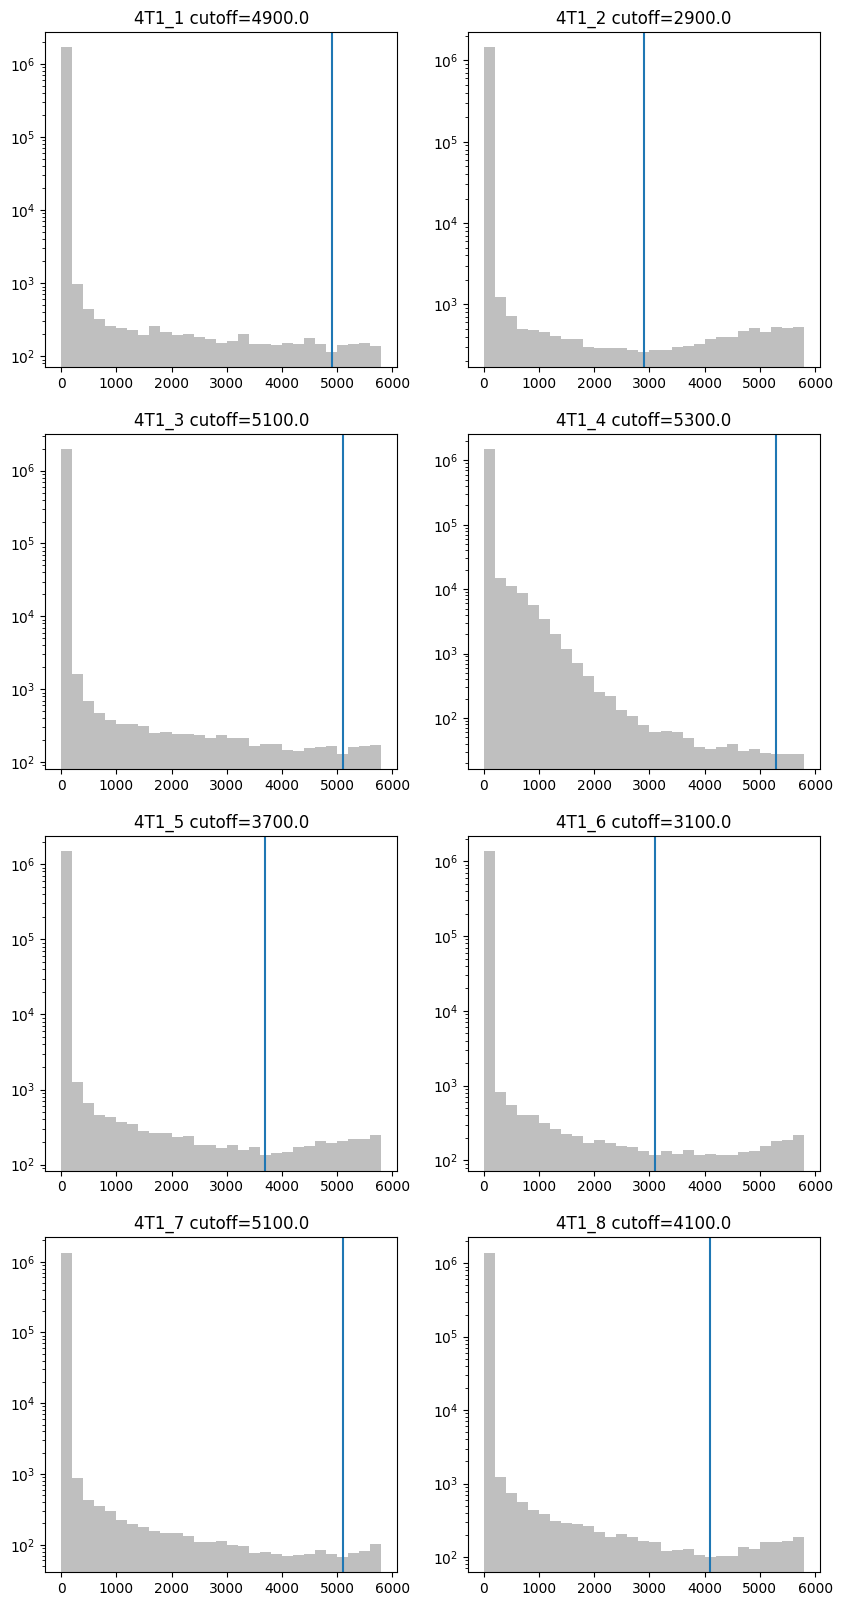

In [21]:
binsize=200
maxx = 6000   # This is upper limit of plot, we want to zoom in on region between size peaks
bins = np.arange(0, maxx, binsize)

# set true to overlay plot with low mtFrac
plotMito=False

cutoffs = []
plt.subplots(nrows=nrows,ncols=ncols,figsize=(ncols*5,nrows*5))
for i in range(len(adatas)):
    plt.subplot(nrows,ncols,i+1)
    vals = np.array(np.sum(adatas[i].X, axis=1)).flatten()
#    vals = vals[vals > 100]
    h = plt.hist(vals, bins=bins, color='gray', alpha=0.5)
    f = adatas[i].obs['mt_frac'] < 0.05
    if plotMito:
        plt.hist(vals[f], bins=bins, color='red', alpha=0.5)
    plt.yscale('log')
    hvals = pd.DataFrame({'xmid':(h[1][1:] + h[1][:-1])/2.0, 'count':h[0]})#.sort_values(by='count')
    minidx = np.argmin(hvals['count'])
    f = hvals['count'] >= 0  # choose all to start
    while (minidx == sum(f)-1):
        f = (f) & (hvals.index != minidx)
        minidx = np.argmin(hvals.loc[f,'count'])
    cutoff = hvals.loc[minidx,'xmid']
    cutoffs.append(cutoff)
    plt.axvline(cutoff)
    sample = adatas[i].obs['sample'].iloc[0]
    plt.title(f'{sample} cutoff={cutoff}')
plt.show()

__This just shows how cutoffs look on the CDF plot__

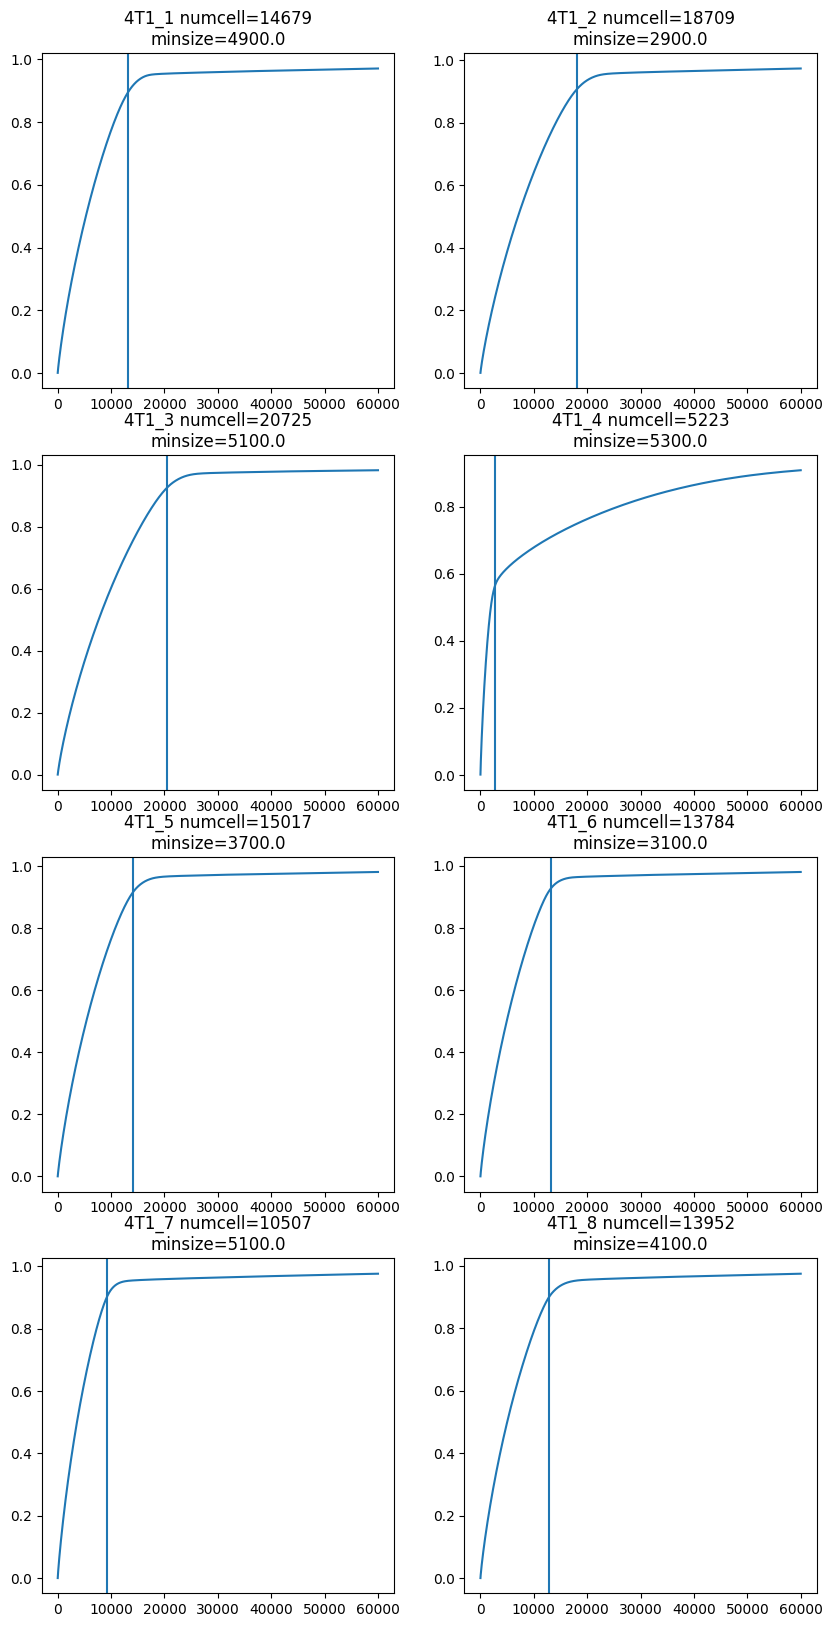

In [22]:
plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
idx=1

for i,s in enumerate(samples):
    plt.subplot(nrows, ncols, idx)
    idx=idx+1
    #maxcells = adatas[i].shape[0]
    maxcells=60000
    molecules = coo_matrix(adatas[i].X)
    sizes = np.array(np.sum(molecules, axis=1)).flatten()*-1.0
    sizes.sort()
    csizes = sizes.cumsum()*-1.0
    csizes = csizes/np.max(csizes)
    kneedle = KneeLocator(np.arange(0, maxcells), csizes[:maxcells])
    #kneedle.plot_knee(plt.gca())
    plt.plot(np.arange(0, maxcells), csizes[:maxcells])
    #plt.axvline(kneedle.knee)
    
    plt.axvline(sum(adatas[i].obs['library_size'] >= cutoffs[i]))
    #print(kneedle.knee)
    minsize = -sizes[kneedle.knee]
    #print(minsize)
    #plt.xlim((0, maxcells))
    plt.title(f'{s} numcell={kneedle.knee}\nminsize={cutoffs[i]}')

0 4T1_1
1 4T1_2
2 4T1_3
3 4T1_4
4 4T1_5
5 4T1_6
6 4T1_7
7 4T1_8


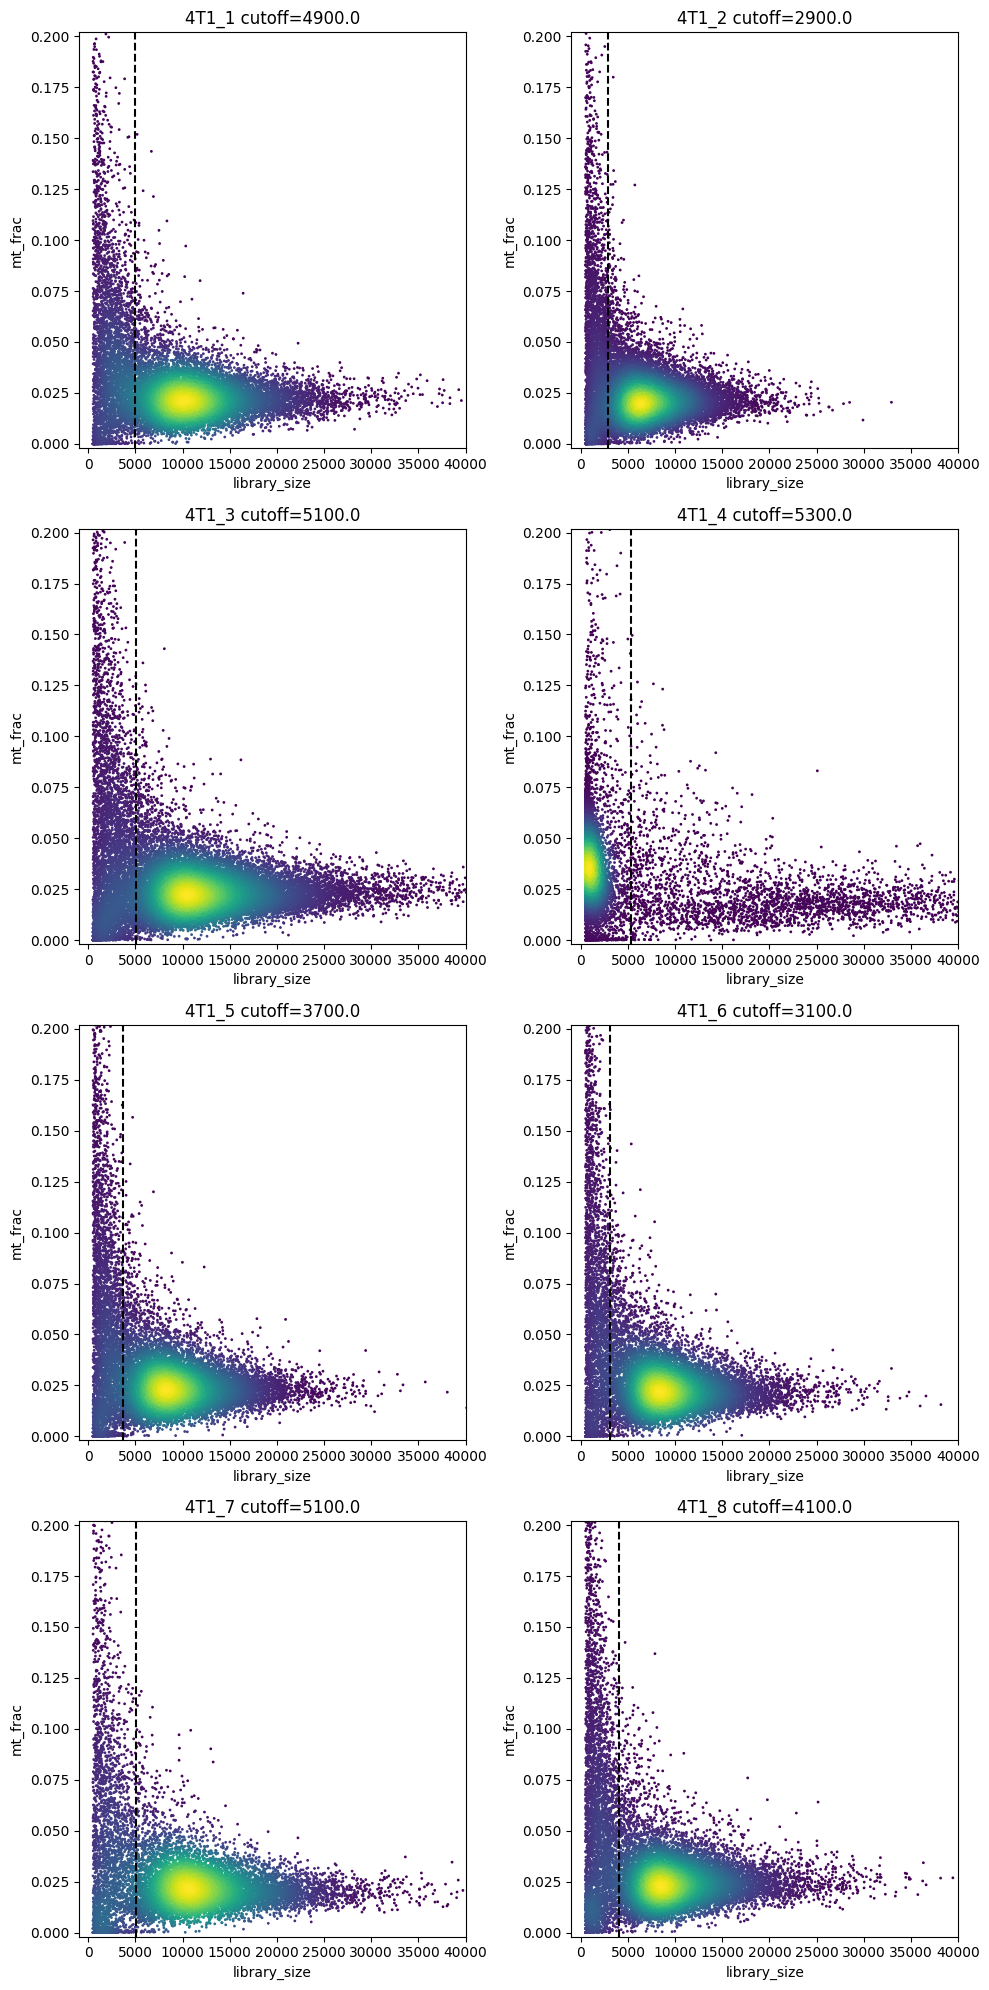

In [23]:
plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
idx=1
maxval = np.max(np.array([np.max(adata.obs['library_size']) for adata in adatas]))
maxmt = np.max(np.array([np.max(adata.obs['mt_frac']) for adata in adatas]))
maxmt=0.2
for i,adata in enumerate(adatas):
    f = adata.obs['library_size'] > 500 # skip very empty cells, otherwise plot_scatter_continuous blows up
    x = np.array(adata.obs.loc[f,'library_size'])
    y = np.array(adata.obs.loc[f,'mt_frac'])
    sample = adata.obs['sample'].iloc[0]
    print(i, sample)
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    scrpr.plot_scatter_continuous(x, y, ax=ax, colorbar=False, s=1)
    ax.set_xlabel('library_size')
    ax.set_ylabel('mt_frac')
    ax.set_title(f'{sample} cutoff={cutoffs[i]}')
    #ax.set_xlim((-maxval*0.01, maxval*1.01))
    ax.set_xlim((-maxval*0.01, 40000.0))
    ax.set_ylim((-maxmt*0.01, maxmt*1.010))
    plt.axvline(cutoffs[i], color='black', linestyle='--')
plt.tight_layout()
plt.show()

__Execute next cell when happy with size filter__

In [24]:
for i in range(len(adatas)):
    adatas[i] = adatas[i][adatas[i].obs['library_size'] >= cutoffs[i]]

In [25]:
adata = sc.concat(adatas, merge='same')
adata.uns['variants'] = variants

__REMOVE 4T1_4 due to quality issues__

In [26]:
if '4T1_4' in samples:
    print('Removing 4T1_4 from dataset')
    adata = adata[adata.obs['sample'] != '4T1_4']
    
    samples = [x for x in samples if x!='4T1_4']
    len(samples)

Removing 4T1_4 from dataset


In [27]:
adata.shape

(100960, 32245)

In [28]:
adata.obs['sample'].value_counts()

sample
4T1_3    20505
4T1_2    18155
4T1_5    14016
4T1_6    13203
4T1_1    13084
4T1_8    12799
4T1_7     9198
Name: count, dtype: int64

## Some cell filtering/quality

### Mitochondrial filter

Cells removed: 0
Cells remaining: 13084
Cells removed: 0
Cells remaining: 18155
Cells removed: 0
Cells remaining: 20505
Cells removed: 0
Cells remaining: 14016
Cells removed: 0
Cells remaining: 13203
Cells removed: 0
Cells remaining: 9198
Cells removed: 0
Cells remaining: 12799


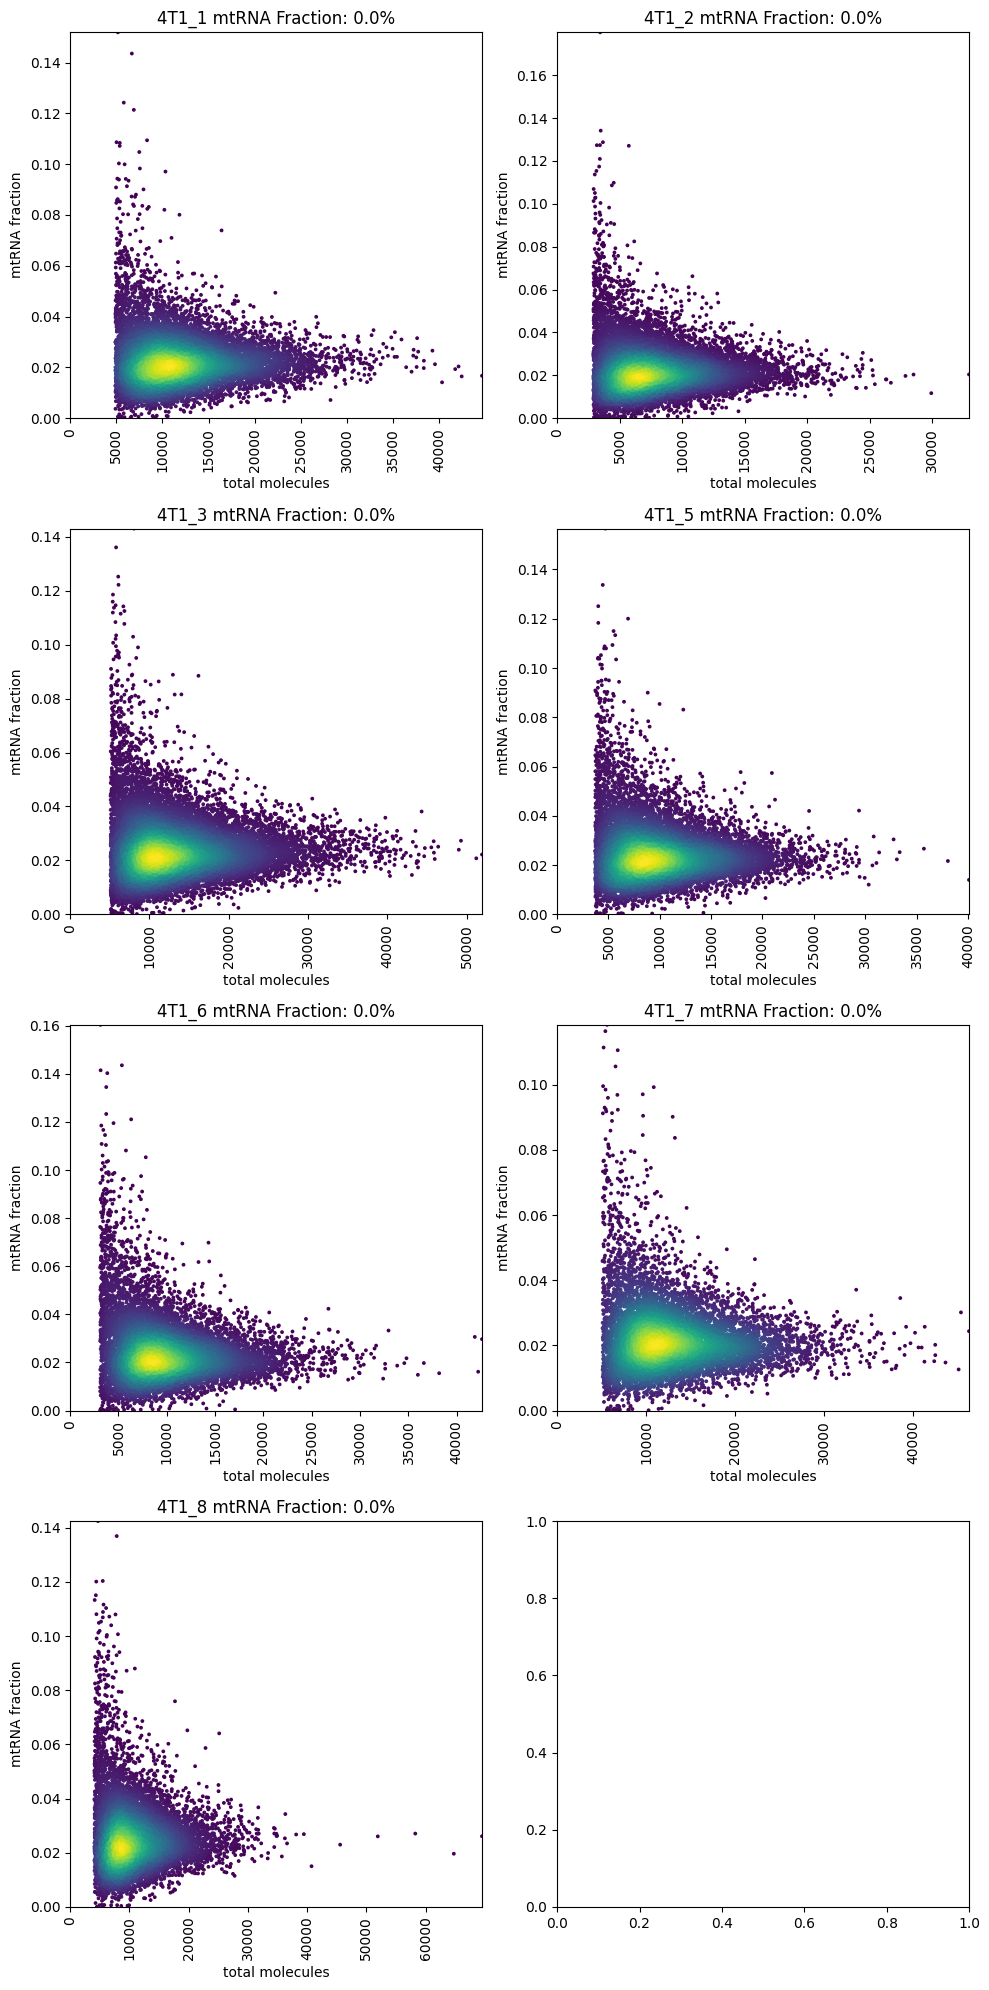

In [29]:
mito_thresh = 0.2
idx=1
fig = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*5, nrows*5))
mt_invalid = {}
for sample in samples:
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    f = adata.obs['sample'] == sample
    mt_invalid[sample] = np.zeros(sum(f), bool)
    low_count_dict = {}
    molecules = coo_matrix(adata[f].X)
    mt_invalid[sample] = scrpr.filter_high_mitochondrial_rna(molecules, genes, mt_invalid[sample], 
                                                     max_mt_content=mito_thresh, plot=True, 
                                                     ax=ax, mt_prefix='mt-')
    print(f"Cells removed: {np.count_nonzero(mt_invalid[sample])}")
    print(f"Cells remaining: {np.count_nonzero(mt_invalid[sample]==0)}")
    ax = plt.gca()
    txt = ax.get_title()
    ax.set_title(sample + ' '  + txt)
    plt.savefig(f'{output_dir}/{celltype}_{condition}_mtFilter.png', dpi=400)
plt.tight_layout()
plt.show()

### coverage filter

ymax=1.4083263946711073
Cells removed: 8
Cells remaining: 13076
Cells failing this filter: 8
ymax=1.3547657512116316
Cells removed: 3
Cells remaining: 18152
Cells failing this filter: 3
ymax=1.3834048640915593
Cells removed: 11
Cells remaining: 20494
Cells failing this filter: 11
ymax=1.398168288494562
Cells removed: 2
Cells remaining: 14014
Cells failing this filter: 2
ymax=1.378066121578386
Cells removed: 7
Cells remaining: 13196
Cells failing this filter: 7
ymax=1.366060606060606
Cells removed: 5
Cells remaining: 9193
Cells failing this filter: 5
ymax=1.3205583155902532
Cells removed: 7
Cells remaining: 12792
Cells failing this filter: 7


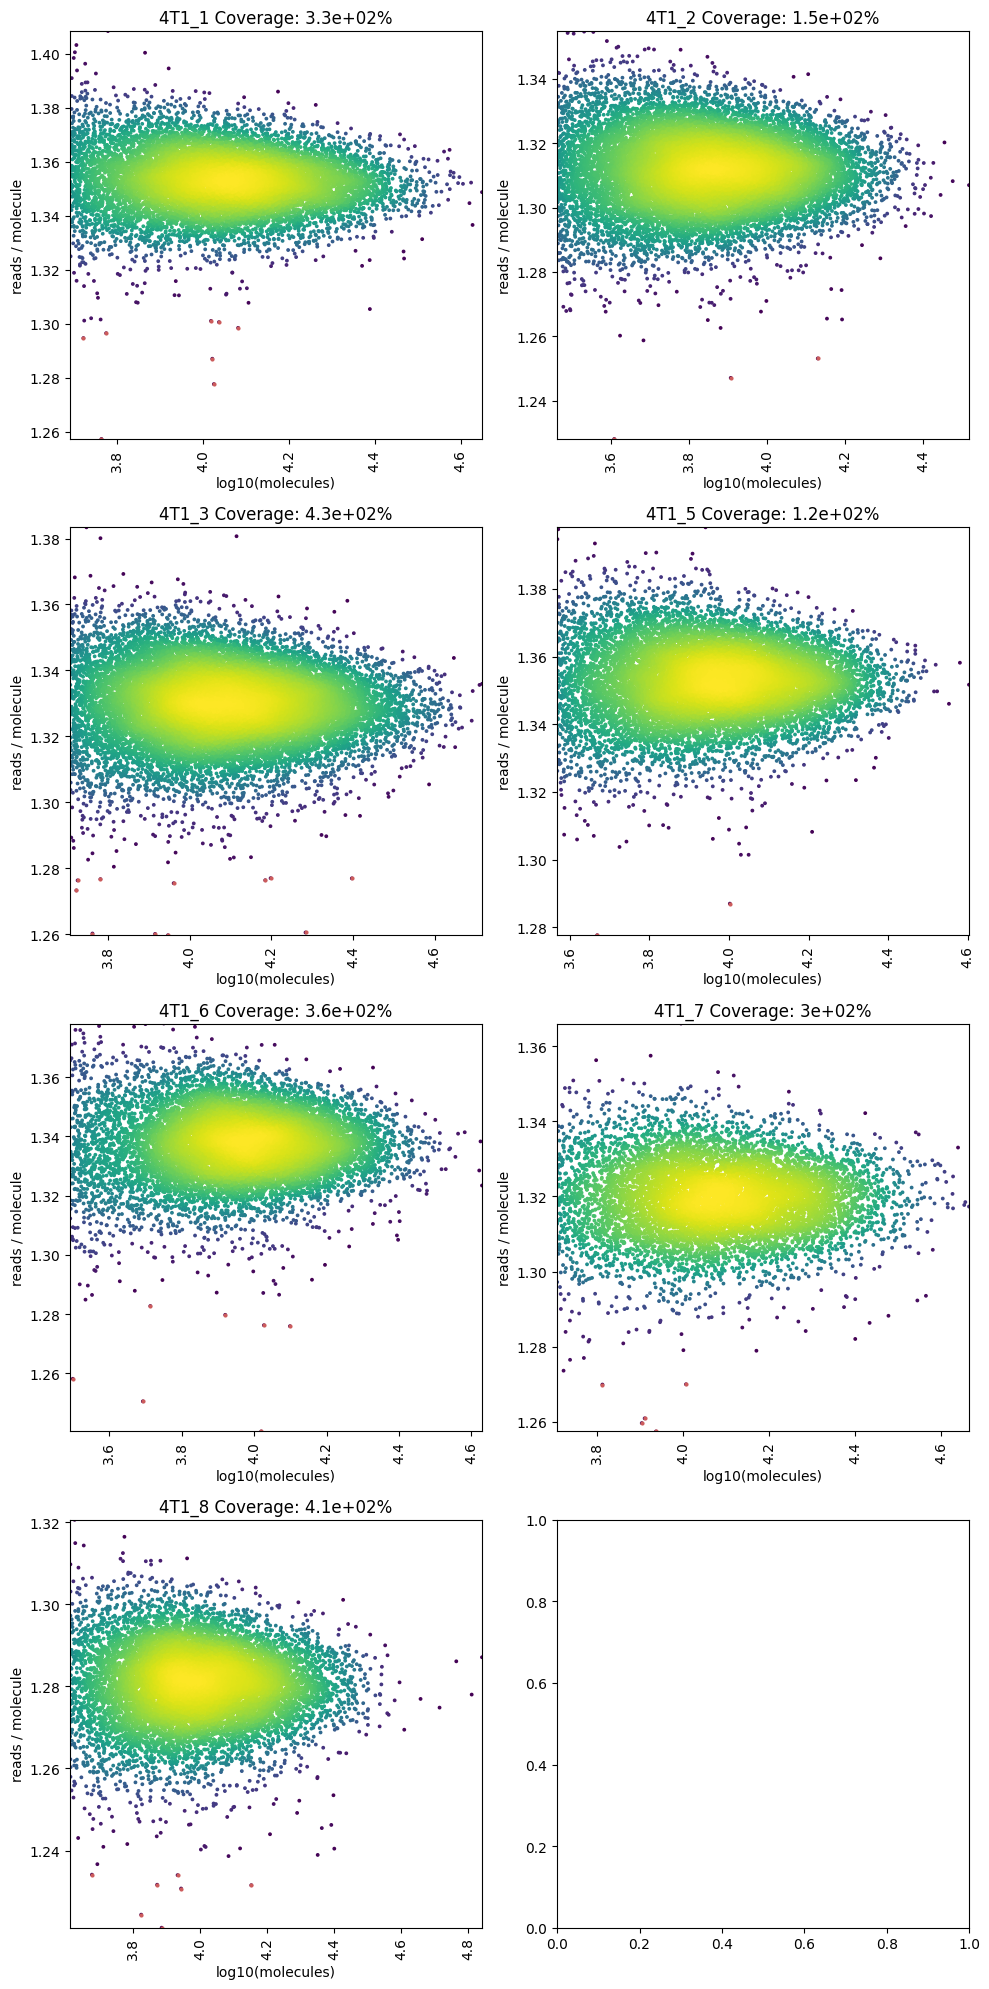

In [30]:
idx=1
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols, 5*nrows))
cov_invalid = {}
for sample in samples:
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    f = adata.obs['sample'] == sample
    molecules = coo_matrix(adata[f].X)
    cov_invalid[sample] = scrpr.filter_low_coverage(molecules, adata[f].layers['read_matrix'], 
                                                    mt_invalid[sample], cutoff=5, plot=True, ax = ax)
    print(f"Cells removed: {np.count_nonzero(cov_invalid[sample])}")
    print(f"Cells remaining: {np.count_nonzero(cov_invalid[sample]==0)}")
    print(f"Cells failing this filter: {sum(cov_invalid[sample]) - sum(mt_invalid[sample])}")
    ax = plt.gca()
    txt = ax.get_title()
    ax.set_title(sample + ' '  + txt)

# SAVE FIGURE
fn = f'{output_dir}/{celltype}_{condition}_readsPerMolecule_vs_size.png'
plt.tight_layout()
plt.savefig(fn, dpi=400)
plt.show()

### Complexity

In [31]:
is_invalid = {}
for sample in samples:
    is_invalid[sample] = (mt_invalid[sample] ) | (cov_invalid[sample])
    print(sample, sum(is_invalid[sample]))

4T1_1 8
4T1_2 3
4T1_3 11
4T1_5 2
4T1_6 7
4T1_7 5
4T1_8 7


Cells removed: 9
Cells remaining: 13075
Cells failing this filter: 1
Cells removed: 4
Cells remaining: 18151
Cells failing this filter: 1
Cells removed: 14
Cells remaining: 20491
Cells failing this filter: 3
Cells removed: 5
Cells remaining: 14011
Cells failing this filter: 3
Cells removed: 9
Cells remaining: 13194
Cells failing this filter: 2
Cells removed: 8
Cells remaining: 9190
Cells failing this filter: 3
Cells removed: 8
Cells remaining: 12791
Cells failing this filter: 1


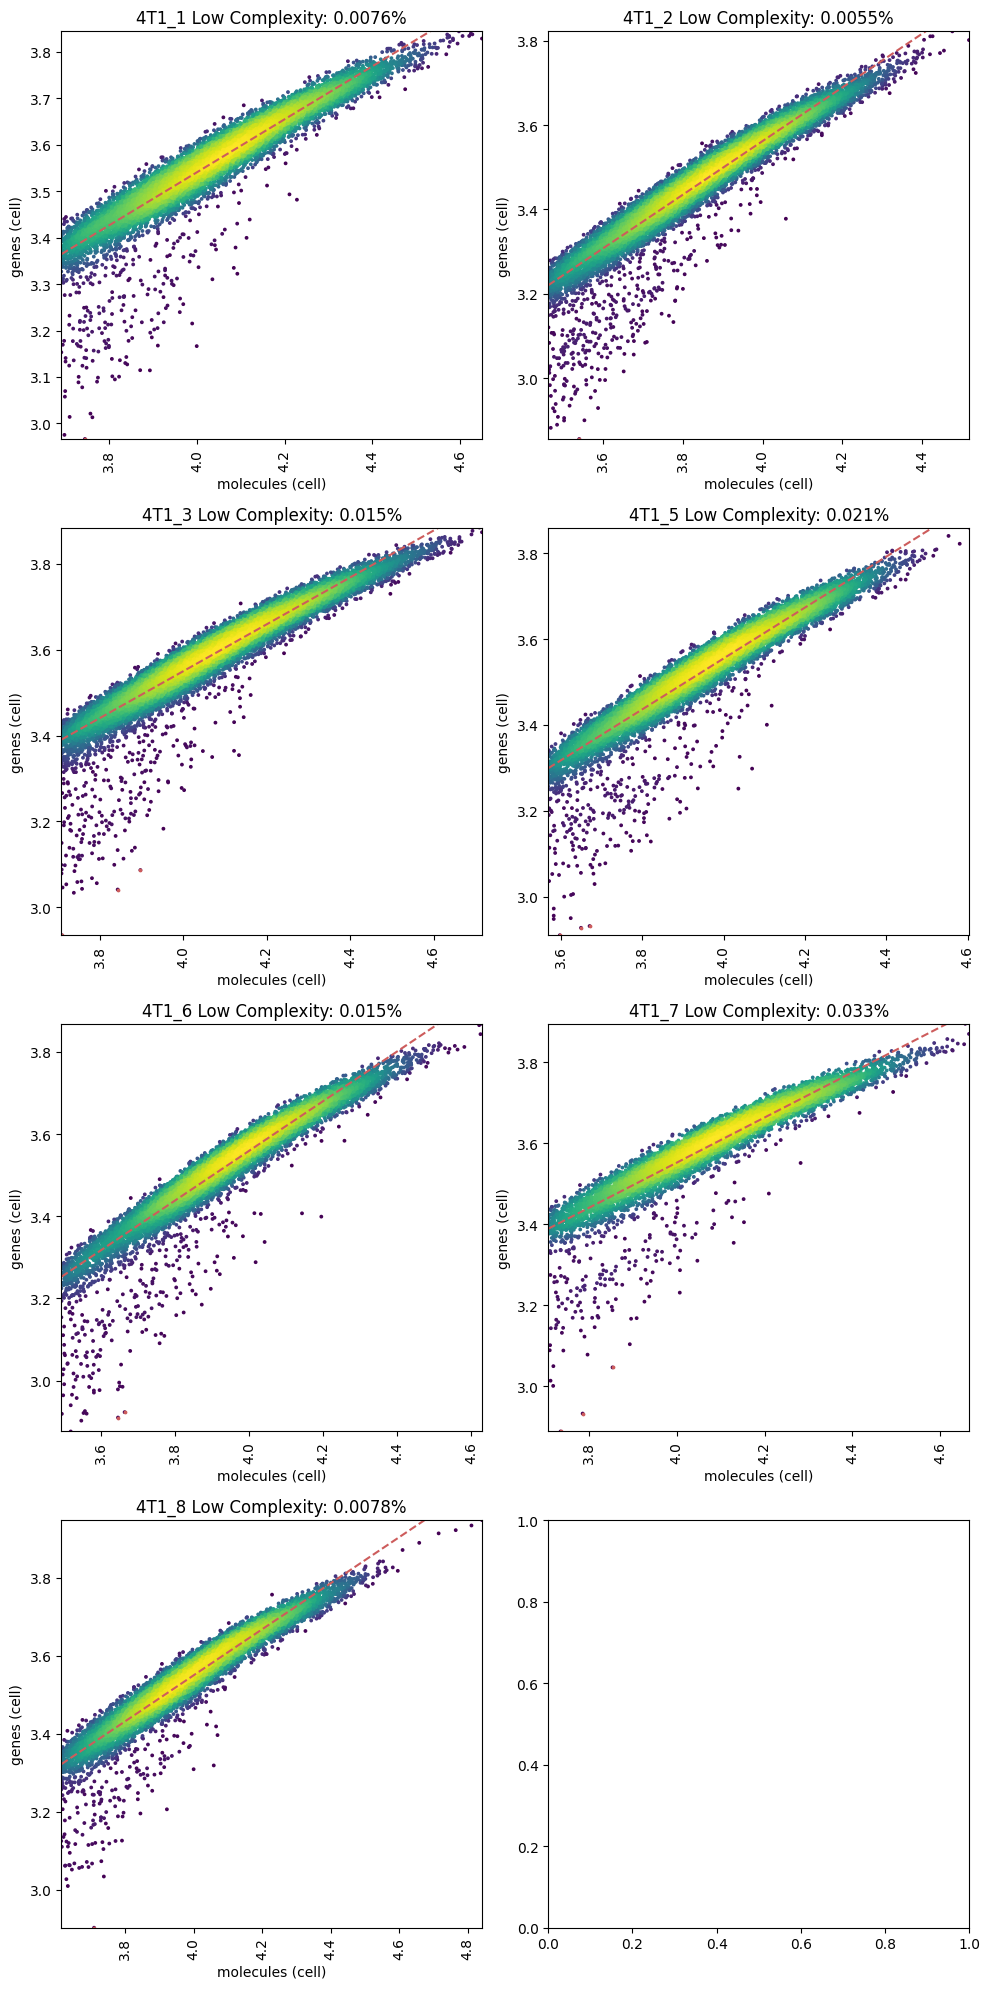

In [32]:
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols, 5*nrows))
idx = 1
complexity_invalid = {}
for sample in samples:
    ax = plt.subplot(nrows, ncols, idx)
    idx=idx+1
    f = adata.obs['sample'] == sample
    molecules = coo_matrix(adata[f].X)
    complexity_invalid[sample] = scrpr.filter_low_gene_abundance(molecules, 
                                                         is_invalid[sample], residual_cutoff=0.40, plot=True, ax=ax)
    print(f"Cells removed: {np.count_nonzero(complexity_invalid[sample])}")
    print(f"Cells remaining: {np.count_nonzero(complexity_invalid[sample]==0)}")
    print(f"Cells failing this filter: {sum(complexity_invalid[sample]) - sum(is_invalid[sample])}")

    ax = plt.gca()
    txt = ax.get_title()
    ax.set_title(sample + ' '  + txt)

fn = f'{output_dir}/{celltype}_{condition}_complexityFilter.png'
plt.tight_layout()
plt.savefig(fn, dpi=400)
plt.show()

In [33]:
for sample in samples:
    is_invalid[sample] = (is_invalid[sample] ) | (complexity_invalid[sample])
    print(sample, sum(is_invalid[sample]))

4T1_1 9
4T1_2 4
4T1_3 14
4T1_5 5
4T1_6 9
4T1_7 8
4T1_8 8


In [34]:
all_invalid = np.zeros(adata.shape[0], bool)
for s in samples:
    f = (adata.obs['sample'] == s)
    all_invalid[f] = is_invalid[s]
adata = adata[~all_invalid]
adata.shape

(100903, 32245)

In [35]:
adata.obs['totReads'] = np.array(np.sum(adata[:,genes].layers['read_matrix'], axis=1)).reshape(-1)
adata.obs['library_size'] = np.squeeze(np.asarray(np.sum(adata[:,genes].X, axis=1)))
adata.layers['X_orig'] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=10000)
adata.layers['X'] = adata.X.copy()
adata.X = adata.layers['X'].copy()

# note: next 3 lines are equivalent to adata.layers['logX'] = np.log10(adata.X+0.1)-np.log10(0.1) = np.log10(10x+1)
adata.X = adata.X*10
sc.pp.log1p(adata, base=10)
adata.layers['logX'] = adata.X.copy()
print(np.max(adata.layers['logX']), np.max(adata.layers['X']))

/tmp/ipykernel_4105/134937359.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['totReads'] = np.array(np.sum(adata[:,genes].layers['read_matrix'], axis=1)).reshape(-1)


4.425505 2663.722


### Parse TWIST variation annotations from CellRanger

The CellRanger output can give us positional variants based on the TWIST barcode read from feature reads

In [36]:
adata

AnnData object with n_obs × n_vars = 100903 × 32245
    obs: 'sample', 'library_size', 'mt_frac', 'totReads'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'variants', 'log1p'
    obsm: 'variant_counts', 'variant_reads'
    layers: 'read_matrix', 'X_orig', 'X', 'logX'

In [37]:
# use reads to call variant, not UMIs
varcol = 'variant_reads'

In [38]:
adata.obs['numVariant'] = np.sum(adata.obsm[varcol] > 0, axis=1)

In [39]:
# most cells have small number of variants, but there is a long tail
adata.obs['numVariant'].value_counts()

numVariant
1     31087
2     24243
0     18088
3     13870
4      6839
5      3169
6      1480
7       777
8       375
9       257
10      157
11      136
12       83
13       65
14       46
15       44
16       27
17       24
18       17
19       13
21       12
20       11
23        8
26        7
24        7
27        7
25        6
29        5
28        5
33        4
36        3
32        3
22        2
31        2
55        2
38        2
30        2
37        2
64        2
41        1
72        1
34        1
57        1
77        1
53        1
48        1
35        1
79        1
61        1
39        1
42        1
90        1
87        1
Name: count, dtype: int64

In [40]:
# assign maxvariant to most frequently observed variant in each cell
adata.obs['maxvariant'] = np.array(variants)[np.argmax(adata.obsm[varcol], axis=1)]
adata.obs.loc[adata.obs['numVariant'] == 0,'maxvariant'] = 'None'

In [41]:
# If two variants have equal numbers of reads, set variant to None
maxval = np.max(adata.obsm[varcol], axis=1)
adata.obs['variant_tied'] = False
adata.obs.loc[adata.obs['numVariant'] == 0,'variant_tied'] = True
for i,idx in enumerate(adata.obs.index):
    if adata.obs.loc[idx,'numVariant'] == 0:
        continue
    if sum(adata.obsm[varcol][i,:] == maxval[i]) > 1:
        adata.obs.loc[idx,'variant_tied'] = True
adata.obs.loc[adata.obs['variant_tied'],'maxvariant'] = 'None'
print(adata.obs['variant_tied'].value_counts())

variant_tied
False    77420
True     23483
Name: count, dtype: int64


In [42]:
# compute variant entropy per cell
adata.obs['entropy'] = 0.0
for i in adata.obs.index:
    tmp = np.array(adata[i].obsm[varcol]).reshape(-1)
    tmp = tmp[tmp > 0]/sum(tmp)
    if len(tmp) <= 1:
        continue
    adata.obs.loc[i,'entropy'] = -np.sum(tmp*np.log(tmp))/np.log(len(tmp))

In [43]:
adata.obs['numvariant_umis'] = np.sum(adata.obsm['variant_counts'], axis=1)
adata.obs['numvariant_reads'] = np.sum(adata.obsm['variant_reads'], axis=1)

Text(0.5, 1.0, 'all cells')

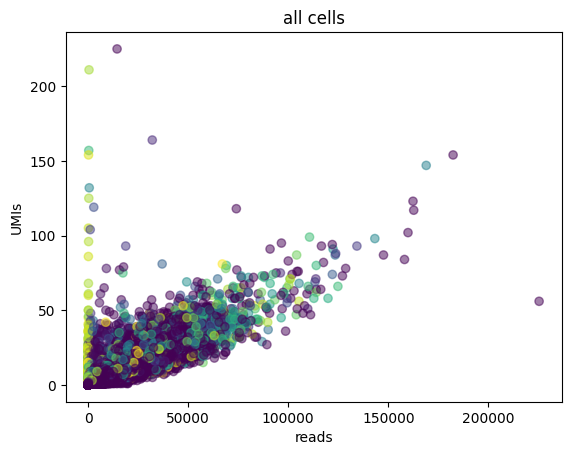

In [44]:
plt.scatter(adata.obs['numvariant_reads'],
            adata.obs['numvariant_umis'], c=adata.obs['entropy'], alpha=0.5)
plt.xlabel('reads')
plt.ylabel('UMIs')
plt.title('all cells')
#plt.xscale('log')
#plt.yscale('log')

Text(0.5, 1.0, 'cells with entropy < 0.7')

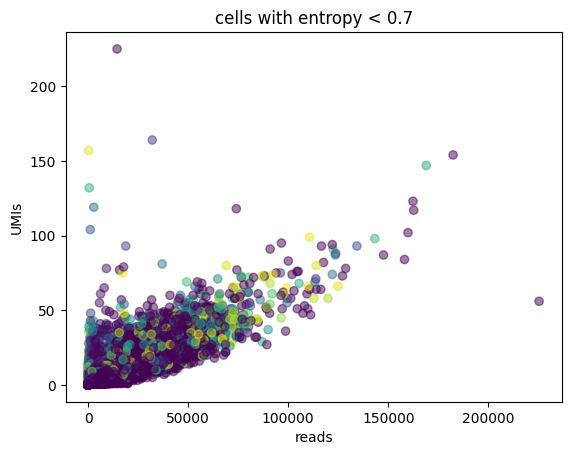

In [45]:
f = adata.obs['entropy'] < 0.7
plt.scatter(adata.obs.loc[f,'numvariant_reads'],
            adata.obs.loc[f,'numvariant_umis'], c=adata.obs.loc[f,'entropy'], alpha=0.5)
plt.xlabel('reads')
plt.ylabel('UMIs')
plt.title('cells with entropy < 0.7')
#plt.xscale('log')
#plt.yscale('log')

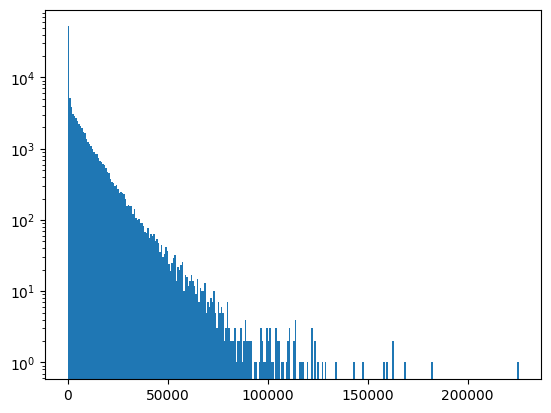

In [46]:
plt.hist(adata.obs['numvariant_reads'], bins=300)
plt.yscale('log')

Text(0, 0.5, 'count')

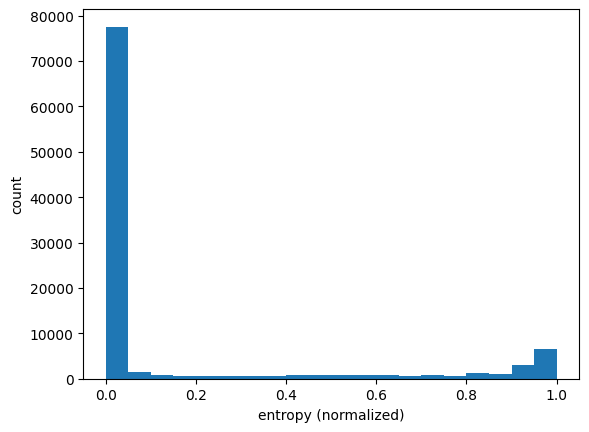

In [47]:
plt.hist(adata.obs['entropy'], bins=20)
plt.xlabel('entropy (normalized)')
plt.ylabel('count')

In [48]:
adata.obs.columns

Index(['sample', 'library_size', 'mt_frac', 'totReads', 'numVariant',
       'maxvariant', 'variant_tied', 'entropy', 'numvariant_umis',
       'numvariant_reads'],
      dtype='object')

In [49]:
f = (adata.obs['entropy'] < 0.7) & (adata.obs['variant_tied']==False) & (adata.obs['numvariant_umis'] > 0)
print(sum(f))
adata.obs['variant_cr'] = 'None'
adata.obs.loc[f,'variant_cr'] = adata.obs.loc[f,'maxvariant'].astype(str)

69563


In [50]:
adata.obs['variant_cr'].value_counts(normalize=False)

variant_cr
None         31340
mSTING_WT     5388
STOP          3337
L56X          1115
L26X           994
             ...  
V143X            2
M1X              1
V301X            1
R333X            1
A287X            1
Name: count, Length: 353, dtype: int64

In [51]:
adata.obs.loc[adata.obs['variant_cr'] != 'None', 'sample'].value_counts()

sample
4T1_3    14249
4T1_2    12678
4T1_5     9852
4T1_6     9617
4T1_1     8953
4T1_8     8135
4T1_7     6079
Name: count, dtype: int64

__Fix bugs in feature_ref_v2 file__

The v2 vesrion has dUPR and dCTT flipped, and also calls A261X mutation just 261X. If cellranger was run with v3, this does not need to be run, so first detect the version (assuming all samples were mapped with same version)

In [52]:
with open(cellranger_out_dir + '/' + samples[0] + '/_cmdline') as f:
     feature_ref = f.read().split("--feature-ref=")[1].split()[0]
if feature_ref.endswith('feature_ref_v2.csv'):
    print('Detected feature_ref_v2, fixing dUPR/dCTT and A261X naming')
    
    fdupr = adata.obs['variant_cr'] == 'dUPR'
    fdctt = adata.obs['variant_cr'] == 'dCTT'
    print(f'Switching {sum(fdupr)} dUPR variants to dCTT')
    print(f'Switching {sum(fdctt)} dCTT variants to dUPR')
    adata.obs.loc[fdupr,'variant_cr'] = 'dCTT'
    adata.obs.loc[fdctt,'variant_cr'] = 'dUPR'
    
    f = adata.obs['variant_cr'].isin(['dUPR', 'dCTT'])
    adata.obs.loc[f,'variant_cr'].astype(str).value_counts()
    
    # A261X was wrongly named 261X in original variant barcode file, fix
    adata.obs['variant_cr'] = adata.obs['variant_cr'].astype(str)
    f = adata.obs['variant_cr'] == '261X'
    print(f'Changing {sum(f)} 261X variants to A261X')
    adata.obs.loc[f, 'variant_cr'] = 'A261X'
else:
    print(f'Detected feature_ref={feature_ref}, no correction needed')

# at this point variant_cr should never be 261X, if it is, might want to check that feature_ref was parsed correc
if sum(adata.obs['variant_cr'] == '261X') != 0:
    print(f'error, feature_ref={feature_ref}, may want to fix')

Detected feature_ref_v2, fixing dUPR/dCTT and A261X naming
Switching 3 dUPR variants to dCTT
Switching 4 dCTT variants to dUPR
Changing 6 261X variants to A261X


## Get clonal barcode

In [53]:
# return fractional distance between bc1 and bc2, correcting for N's 
def barcode_distance(bc1, bc2):
    numn1 = bc1.count('N')
    numn2 = bc2.count('N')
    ndiff = int(np.abs(numn1 - numn2))
    return editdistance.eval(bc1, bc2)-ndiff

In [54]:
os.getcwd()

'/workdir/satseq/satseq_processing'

In [55]:
# This new version has dUPR/dCTT fixed and A261X fixed
twist=pd.read_csv('data/twist_mSTING_full_feature_ref_v3.csv', index_col=0)
twist

,name,read,pattern,sequence,feature_type
id,,,,,
SSBC0000,mSTING_WT,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),CGAGGAATTAGCAACG,Custom
SSBC0001,STOP,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GTAATGAATACCGAGG,Custom
SSBC0002,V146L,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),TGGCGGCGAATATAGC,Custom
SSBC0003,N153S,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),CCTCGAGAACTTTCCT,Custom
SSBC0004,V154M,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GGAATCAGACTGAAAC,Custom
...,...,...,...,...,...
T48BC374,R374X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GCTAACCAACTACCTC,Custom
T48BC375,T375X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),TGTAACATCCGTCGAA,Custom
T48BC376,D376X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GAGTTACTCATCGTCT,Custom


In [56]:
twistpos = twist.set_index('name', drop=True).copy()
twistpos['pos'] = 0
for i in twistpos.index:
    val=-5
    if i=='mSTING_WT':
        val=-5
    elif i=='STOP':
        val=-4
    elif i=='RRDD':
        val=-3
    elif i=='RRAA':
        val=-2
    elif i=='dCTT':
        val=-1
    elif i=='dUPR':
        val=0
    else:
        val=int(i[1:-1])
    twistpos.loc[i,'pos']=val
# add this entry
twistpos.loc['_379X','pos'] = 379

In [57]:
spikeIns = [x for x in twist['name'] if not x.endswith('X')]
spikeIns

['mSTING_WT',
 'STOP',
 'V146L',
 'N153S',
 'V154M',
 'S161A',
 'I229A',
 'Y239S',
 'N241A',
 'S365A',
 'RRAA',
 'RRDD',
 'dCTT',
 'dUPR']

In [58]:
nonPositionalSpikeIns=[x for x in twist['name'] if not x[1:-1].isnumeric()]
nonPositionalSpikeIns

['mSTING_WT', 'STOP', 'RRAA', 'RRDD', 'dCTT', 'dUPR']

In [59]:
# Read in consensus barcode for each cell
barcoderef='AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNCGCTNNNNNNNNNNNNNNNNCGCTTTAAGGCCGGTCCTAGCAA'
adata.obs['consensus_barcode'] = ''
adata.obs['consensus_barcode_twist'] = ''
for s in adata.obs['sample'].unique():
    fname=cellranger_out_dir + '/' + s  + '/outs/barcode_consensus_simple_bothref.fa.gz'
    if not os.path.exists(fname):
        print(f'Error: {fname} not found')
        continue
    print(f'Reading barcodes from {fname}')
    suffix = '-' + adata.obs.loc[adata.obs['sample'] == s].index[0].split('-')[-1]    
    cellname=''
    not_found=0
    found=0
    found_twist=0
    num_good_align=0  
    with gzip.open(fname, 'rt') as f:
        for line in f:
            if line.startswith('>'):
                cell=line.strip()[1:] + suffix
            else:
                barcodeseq=line
                if barcodeseq[:20] == barcoderef[:20] and barcodeseq[56:76] == barcoderef[56:76]:
                    num_good_align=num_good_align+1
                cellbarcode = barcodeseq[20:56]
                if cell in adata.obs.index:
                    #if adata.obs.loc[cell,'consensus_barcode'] != '':
                    #    print(f'error {cell}')
                    adata.obs.loc[cell,'consensus_barcode'] = cellbarcode
                    found=found+1
                    f = twist['sequence'].str.contains(cellbarcode[20:36])
                    if sum(f) == 1:
                        found_twist=found_twist+1
                        adata.obs.loc[cell, 'consensus_barcode_twist'] = twist.loc[f,'name'].iloc[0]
                else:
                    not_found=not_found+1
    f = adata.obs['sample'] == s
    f2 = adata.obs['consensus_barcode'] != ''
    diffcall = ((adata.obs['consensus_barcode_twist'] != adata.obs['variant_cr']) & 
                (adata.obs['variant_cr'] != 'None') & 
                (adata.obs['consensus_barcode_twist'] != ''))

    print(f'num_found={found} found_twist={found_twist} not_found={not_found} num_good_align={num_good_align} frac_cells={sum(f & f2)/sum(f)} diffcalls={sum(diffcall)}')

Reading barcodes from /workdir/satseq/Laughney-MD-16637_2024_06_11/4T1/4T1_1/outs/barcode_consensus_simple_bothref.fa.gz
num_found=11630 found_twist=7686 not_found=128380 num_good_align=80914 frac_cells=0.8894837476099426 diffcalls=0
Reading barcodes from /workdir/satseq/Laughney-MD-16637_2024_06_11/4T1/4T1_2/outs/barcode_consensus_simple_bothref.fa.gz
num_found=16222 found_twist=10889 not_found=115653 num_good_align=78586 frac_cells=0.8937248636438764 diffcalls=0
Reading barcodes from /workdir/satseq/Laughney-MD-16637_2024_06_11/4T1/4T1_3/outs/barcode_consensus_simple_bothref.fa.gz
num_found=18318 found_twist=12193 not_found=108139 num_good_align=80277 frac_cells=0.8939534429749646 diffcalls=0
Reading barcodes from /workdir/satseq/Laughney-MD-16637_2024_06_11/4T1/4T1_5/outs/barcode_consensus_simple_bothref.fa.gz
num_found=12913 found_twist=8202 not_found=120216 num_good_align=75689 frac_cells=0.9216330026407823 diffcalls=0
Reading barcodes from /workdir/satseq/Laughney-MD-16637_2024_0

In [60]:
# This is the fraction of cells with a consensus barcode - for the rest, we will not be able to 
# assign a specific mutation
sum(adata.obs['consensus_barcode'] != '')/adata.obs.shape[0]

0.8841065181411851

In [61]:
# These are the cells where the last 16 bp of the barcode are a perfect match to one of the TWIST barcodes - it is assigned to TWIST variant
sum(adata.obs['consensus_barcode_twist'] != '')/adata.obs.shape[0]

0.5920834861203333

In [62]:
# Should see almost perfect agreement between variant called from conensus barcode TWIST sequence
# and variant called by cellranger
(sum(adata.obs['consensus_barcode_twist'] == adata.obs['variant_cr']))/(
    sum((adata.obs['consensus_barcode_twist']!='') & (adata.obs['variant_cr'] != 'None')))

0.9999830603221926

In [63]:
# what are the exceptions ?
adata.obs.loc[(adata.obs['consensus_barcode_twist'] != '') & (adata.obs['consensus_barcode_twist'] != adata.obs['variant_cr']) & (adata.obs['variant_cr'] != 'None')]

,sample,library_size,mt_frac,totReads,numVariant,maxvariant,variant_tied,entropy,numvariant_umis,numvariant_reads,variant_cr,consensus_barcode,consensus_barcode_twist
GGCAAAGTCACGCTAA-1-5,4T1_6,8744.0,0.006747,11701,2,S128X,False,0.249882,3.0,96,S128X,NNNGNNNCNGCNCTNNAGAACGAGGAATTAGCAACG,mSTING_WT


## Map consensus barcode to pacbio variant map

In [64]:
# Set bcmapfile to the file output by pacbio parsing notebook

bcmapfile = f'/workdir/satseq/long_read/bcmap_{celltype}_2025_02_27.txt.gz'

bcmap = pd.read_csv(bcmapfile, index_col=0,sep='\t')[['aa_mut', 'score', 'closest_variant', 'vardist']]
print(bcmap.shape)
if sum(bcmap['aa_mut'].isin(nonPositionalSpikeIns)) > 0:
    # spike-ins should be removed from map already
    print("error")

(524208, 4)


In [65]:
# Create fasta file with each barcode map
bcmapfa = bcmapfile.replace('.txt.gz', 'fa')
with open(bcmapfa, 'w') as outf:
    for bc in bcmap.index:
        call=bcmap.loc[bc,'aa_mut']
        outf.write(f'>{call}:{bc}\n{bc}\n')

In [66]:
!head -n 12 {bcmapfa} 

>L197P:AAAAAAAAAAAAGGACCGCTCGCCAAGATACTAAGC
AAAAAAAAAAAAGGACCGCTCGCCAAGATACTAAGC
>S242F:AAAAAAAAAACGGCGGCGCTGCATCAACGTGGACTT
AAAAAAAAAACGGCGGCGCTGCATCAACGTGGACTT
>Y260M:AAAAAAAAATTAAACACGCTACTAGCGACTATGTGG
AAAAAAAAATTAAACACGCTACTAGCGACTATGTGG
>M131E:AAAAAAAACGGACACGCGCTCAGTTGAACGGTCTAT
AAAAAAAACGGACACGCGCTCAGTTGAACGGTCTAT
>E259A:AAAAAAAAGAGGGCAGCGCTATCCTCGTCAAACAGG
AAAAAAAAGAGGGCAGCGCTATCCTCGTCAAACAGG
>E55W:AAAAAAAAGATGAGCGCGCTTTCTCCATAGGTTCCT
AAAAAAAAGATGAGCGCGCTTTCTCCATAGGTTCCT


### First get perfect matches

If the cell has exact barcode in barcode map, then assigning variant is easy

In [67]:
bcmap

,aa_mut,score,closest_variant,vardist
bc,,,,
AAAAAAAAAAAAGGACCGCTCGCCAAGATACTAAGC,L197P,100.000000,L197X,0.0
AAAAAAAAAACGGCGGCGCTGCATCAACGTGGACTT,S242F,100.301030,S242X,0.0
AAAAAAAAATTAAACACGCTACTAGCGACTATGTGG,Y260M,100.000000,Y260X,0.0
AAAAAAAACGGACACGCGCTCAGTTGAACGGTCTAT,M131E,100.778151,M180X,0.0
AAAAAAAAGAGGGCAGCGCTATCCTCGTCAAACAGG,E259A,100.107970,E259X,0.0
...,...,...,...,...
TTTTTTTTTTACGTTTCGCTCGATCCTCCGTCAAAC,L51P,100.301030,L51X,0.0
TTTTTTTTTTAGTTGTCGCTATCCTCGCCCAAGTAT,P40V,100.000000,P40X,0.0
TTTTTTTTTTATCGCGCGCTACTCTCTCTTCCGTCA,A253T,100.000000,A253X,0.0


In [68]:
adata.obs.columns

Index(['sample', 'library_size', 'mt_frac', 'totReads', 'numVariant',
       'maxvariant', 'variant_tied', 'entropy', 'numvariant_umis',
       'numvariant_reads', 'variant_cr', 'consensus_barcode',
       'consensus_barcode_twist'],
      dtype='object')

In [69]:
adata.shape

(100903, 32245)

In [70]:
# all cells returned here have perfect matches
adata.obs.reset_index().rename(columns={'index':'cell'}
                                    ).merge(bcmap, left_on='consensus_barcode',right_index=True)

,cell,sample,library_size,mt_frac,totReads,numVariant,maxvariant,variant_tied,entropy,numvariant_umis,numvariant_reads,variant_cr,consensus_barcode,consensus_barcode_twist,aa_mut,score,closest_variant,vardist
0,AAACCAAAGATTACCG-1-0,4T1_1,8396.0,0.032992,11435,1,Y260X,False,0.000000,8.0,7705,Y260X,TTATGGAGCTTGAATCCGCTACTAGCGACTATGTGG,Y260X,P252V,100.828613,Y260X,0.0
2,AAACCAAAGTGGCAGA-1-0,4T1_1,13314.0,0.024185,18236,1,F25X,False,0.000000,7.0,12066,F25X,CCACCGGCCCACTATTCGCTTTCAAGCCGGTGTTCC,F25X,F25M,901.757866,F25X,0.0
5,AAACCATTCCGCACAG-1-0,4T1_1,12354.0,0.030112,16588,2,F268X,False,0.003552,13.0,22494,F268X,TGCTTCCAGCTATTGTCGCTCAACTGTTTCACACCA,F268X,F268N,901.902497,F268X,0.0
6,AAACCATTCGAACCGT-1-0,4T1_1,5273.0,0.018206,7164,1,C91X,False,0.000000,1.0,3,C91X,GTTTATACCTTAGGTACGCTATGTGATGCTAGAGAG,C91X,C91A,801.662920,C91X,0.0
7,AAACCATTCGCGCATG-1-0,4T1_1,5338.0,0.035969,7219,2,L197X,False,0.684038,2.0,11,L197X,CGAACTGCTAGTACTTCGCTCGCCAAGATACTAAGC,L197X,L197M,901.419614,L197X,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100887,TGTGGTTGTGGGTCGA-1-7,4T1_8,8425.0,0.025638,10786,1,L329X,False,0.000000,1.0,6,L329X,CGCTCGTGGGCATTGTCGCTAGGTGTTGCGACTCTT,L329X,L329T,902.746274,L329X,0.0
100895,TGTGTACGTTTCCTGC-1-7,4T1_8,15464.0,0.036860,19627,2,K45X,False,0.001742,7.0,8304,K45X,TGCTATGTAACGATCTCGCTGTCTAACCCTCTCATA,K45X,K45H,901.724810,K45X,0.0
100898,TGTGTTAGTTGCGTGC-1-7,4T1_8,5997.0,0.029015,7699,1,K45X,False,0.000000,1.0,1,K45X,CGCATACCAGCTAAGTCGCTGTCTAACCCTCTCATA,K45X,K45G,101.301030,K45X,0.0
100899,TGTGTTGAGCCAGTAC-1-7,4T1_8,7678.0,0.023053,9880,1,L26X,False,0.000000,1.0,101,L26X,CATGTTTTAGAAGTTGCGCTACTTGTGCCGAGTCAT,L26X,L26P,902.199949,L26X,0.0


In [71]:
mrcols = ['cell', 'variant', 'variant2', 'twist_mut', 'twist_closest_dist', 'corrected_barcode', 'edist', 'edist_n']
tmp = adata.obs.reset_index().rename(columns={'index':'cell'}
                                    ).merge(bcmap, left_on='consensus_barcode',right_index=True)[[
    'cell', 'aa_mut', 'closest_variant', 'vardist', 'consensus_barcode']].rename(columns={'aa_mut':'variant',
                                                                                              'closest_variant':'twist_mut',
                                                                                              'vardist':'twist_closest_dist'})
tmp['variant2'] =[','.join([y[:-1]+'X' for y in x.split(',')]) for x in tmp['variant']]
tmp['corrected_barcode'] = tmp['consensus_barcode'].copy()
tmp['edist'] = 0
tmp['edist_n'] = 0
mrFinal = tmp[mrcols]

In [72]:
# This fraction of cells has a consensus barcode, the rest we will not be able to map
f = adata.obs['consensus_barcode'] != ''
print(sum(f)/adata.obs.shape[0])

0.8841065181411851


In [73]:
# This fraction of mappable cells has a perfect match to pacbio map
mrFinal.shape[0]/sum(f)

0.5573092400990931

In [74]:
mrFinal.shape

(49717, 8)

In [75]:
# These are ones that we may be able to map if we look for close matches between cell barcodes and pacbio map
(adata.shape[0] - mrFinal.shape[0]) - sum(adata.obs['consensus_barcode'] == '')

39492

In [76]:
!mkdir -p {output_dir}/NOBACKUP

In [77]:
havecell = (mrFinal['cell'])
f = (~adata.obs.index.isin(havecell)) & (adata.obs['consensus_barcode'] != '')
print(sum(f)) # should match above
queryfa = f'{output_dir}/NOBACKUP/query_{celltype}_{condition}.fa'
with open(queryfa, 'w') as outf:
    for i in adata.obs.loc[f].index:
        outf.write('>' + adata.obs.loc[i].name + '\n')
        outf.write(adata.obs.loc[i,'consensus_barcode'] + '\n')
        

39492


In [78]:
# use mmseqs to search for alignments between pacbio and 10x barcodes
t0 = time.time()
cmd=f'{mmseqs_executable} easy-search --strand 1 --comp-bias-corr 0 --mask 0 --mask-profile 0'
cmd += f' --min-aln-len 30 -c 0.8 -k 6 --search-type 3 {queryfa} {bcmapfa}'
cmd += f' {output_dir}/NOBACKUP/alnRes_{celltype}_{condition}.m8 {output_dir}/NOBACKUP/tmp_{celltype}_{condition}'
print(cmd)
!{cmd}
t1 = time.time()
print(f'alignment time={t1-t0:.1f}s')


/opt/mmseqs/bin/mmseqs easy-search --strand 1 --comp-bias-corr 0 --mask 0 --mask-profile 0 --min-aln-len 30 -c 0.8 -k 6 --search-type 3 /workdir/satseq/10x_processing/NOBACKUP/query_4T1_tumor.fa /workdir/satseq/long_read/bcmap_4T1_2025_02_27fa /workdir/satseq/10x_processing/NOBACKUP/alnRes_4T1_tumor.m8 /workdir/satseq/10x_processing/NOBACKUP/tmp_4T1_tumor
/workdir/satseq/10x_processing/NOBACKUP/alnRes_4T1_tumor.m8 exists and will be overwritten
easy-search --strand 1 --comp-bias-corr 0 --mask 0 --mask-profile 0 --min-aln-len 30 -c 0.8 -k 6 --search-type 3 /workdir/satseq/10x_processing/NOBACKUP/query_4T1_tumor.fa /workdir/satseq/long_read/bcmap_4T1_2025_02_27fa /workdir/satseq/10x_processing/NOBACKUP/alnRes_4T1_tumor.m8 /workdir/satseq/10x_processing/NOBACKUP/tmp_4T1_tumor 

MMseqs Version:                        	8ef870f95af2a3ee474c2cdbb845f5f007fe5be6
Substitution matrix                    	aa:blosum62.out,nucl:nucleotide.out
Add backtrace                          	false
Alignment m

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [79]:
output_dir

'/workdir/satseq/10x_processing'

In [80]:
mr = pd.read_csv(f'{output_dir}/NOBACKUP/alnRes_{celltype}_{condition}.m8', sep='\t')
print(f'mr.shape={mr.shape}')
mr.columns=['cell', 'tbc', 'perc', 'len', 'mismatch', 'gapopen', 'qstart', 'qend', 'tstart', 'tend', 'evalue', 'bitscore']            
#f = (mr['qstart'] > 5) | (mr['tstart'] > 5) | (mr['qend'] < 30) | (mr['tend'] < 30)
#mr = mr.loc[~f]
print(f'filter for qstart/tsrat/qend/tend, now mr.shape={mr.shape}')
mr['variant'] = [x.split(':')[0] for x in mr['tbc']]
mr['variant2'] = [','.join([y[:-1]+'X' for y in x.split(',')]) for x in mr['variant']]
mr['corrected_barcode'] = [x.split(':')[1] for x in mr['tbc']]
mr.drop(columns=['tbc'], inplace=True)

# add barcode map data
mr = mr.merge(bcmap, left_on='corrected_barcode', right_index=True, how='left').drop(columns=['aa_mut']).rename(columns={'closest_variant':'twist_mut',
                                                                                                                         'vardist':'twist_closest_dist'})

print(f'mr.shape={mr.shape}')

mr.shape=(46693, 12)
filter for qstart/tsrat/qend/tend, now mr.shape=(46693, 12)
mr.shape=(46693, 17)


Text(0, 0.5, 'count')

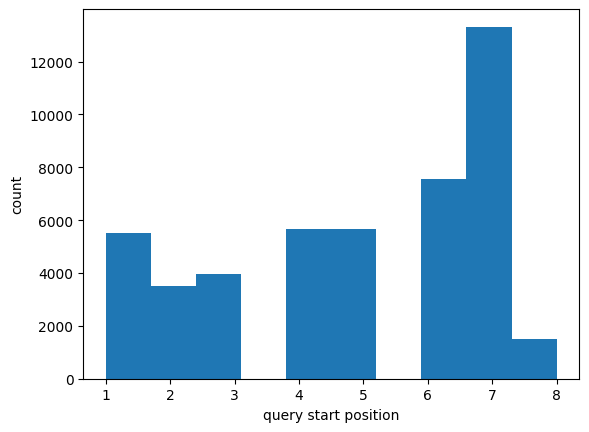

In [81]:
# What position in the barcode does the alignment start?
plt.hist(mr['qstart'])
plt.xlabel('query start position')
plt.ylabel('count')

In [82]:
# remove all but the best scores (keeping ties)
mr = mr.merge(mr[['cell', 'bitscore']].groupby('cell').max().reset_index(),
    left_on='cell', right_on='cell', suffixes=('', '_max')).sort_values(by=['cell', 'evalue'])
mr = mr.loc[mr['bitscore'] == mr['bitscore_max']].drop(columns='bitscore_max')
print(mr.shape[0], len(mr['cell'].unique()))

6474 5715


In [83]:
# compute edit distance for each alignment
# edist is number of edits
# edist_n is number of edits excluding Ns
mr['edist']=-1
for i in mr.index:
    mr.loc[i,'edist'] = editdistance.eval(adata.obs.loc[mr.loc[i,'cell'],'consensus_barcode'], mr.loc[i,'corrected_barcode'])
    mr.loc[i,'edist_n'] = barcode_distance(adata.obs.loc[mr.loc[i,'cell'],'consensus_barcode'], mr.loc[i,'corrected_barcode'])

In [84]:
# Add aligned cells to mrFinal, which so far only contains perfect matches

# First add all cells that have a single entry, these are easiest. Remove these from the mr dataframe.
tmp = mr['cell'].value_counts()
goodCells = tmp[tmp==1].index
tmp=mr.loc[mr['cell'].isin(goodCells)].copy()
mrFinal = pd.concat([mrFinal, tmp[mrcols]])
mr = mr.loc[~mr['cell'].isin(goodCells)]
print(mrFinal.shape[0], mr.shape[0])

54902 1289


In [85]:
# Now mr only contains tied mappings (by mrsearch alignment distance). Keep one with highest pacbio score:
maxcount = mr[['cell', 'score']].groupby('cell').max()
mr = mr.merge(maxcount, left_on='cell', right_index=True, suffixes=('','_max')).sort_values(by=['score'], ascending=False)
mr = mr.loc[mr['score'] == mr['score_max']]
tmp = mr['cell'].value_counts()
keepCell = list(tmp[tmp==1].index)
tmp = mr.loc[(~mr['cell'].duplicated()) & (mr['cell'].isin(keepCell))].copy()
mrFinal = pd.concat([mrFinal, tmp[mrcols]])
mr = mr.loc[~mr['cell'].isin(keepCell)]
print(mrFinal.shape[0], mr.shape[0])

55334 206


In [86]:
# Now everything in mr has multiple entries per cell with same alignment and pacbio scores.
# In some cases they may all point to the same mutation, so keep the one observed the most (if not tied)
mr1 = mr[['cell', 'variant']].value_counts().reset_index()
mrmax = mr1[['cell', 'count']].groupby('cell').max().reset_index()
mr1 = mr1.merge(mrmax, on='cell', suffixes=('', '_max'))
mr1 = mr1.loc[mr1['count'] == mr1['count_max']]
tmp = mr1['cell'].value_counts()
keepCells = tmp[tmp==1].index
mr1 = mr1.loc[mr1['cell'].isin(keepCells)]
tmp = mr[mrcols].merge(mr1[['cell', 'variant']], on=['cell', 'variant']).sort_values(by=['cell', 'twist_closest_dist'])
tmp = tmp[~tmp[['cell', 'variant']].duplicated()]
mrFinal = pd.concat([mrFinal, tmp])
mr = mr.loc[~mr['cell'].isin(keepCells)]
print(mrFinal.shape[0], mr.shape[0])

55350 172


In [87]:
# In some cases they disagree about exact mutation, but agree on position,
# so use variant2, which has resultant AA replaced with X
mr1 = mr[['cell', 'variant2']].value_counts().reset_index()
mrmax = mr1[['cell', 'count']].groupby('cell').max().reset_index()
mr1 = mr1.merge(mrmax, on='cell', suffixes=('', '_max'))
mr1 = mr1.loc[mr1['count'] == mr1['count_max']]
tmp = mr1['cell'].value_counts()
keepCells = tmp[tmp==1].index
mr1 = mr1.loc[mr1['cell'].isin(keepCells)]
tmp = mr[mrcols].merge(mr1[['cell', 'variant2']], on=['cell', 'variant2']).sort_values(by=['cell', 'twist_closest_dist'])
tmp = tmp[~tmp[['cell', 'variant2']].duplicated()]
tmp['variant'] = tmp['variant2']
mrFinal = pd.concat([mrFinal, tmp])
mr = mr.loc[~mr['cell'].isin(keepCells)]
print(mrFinal.shape[0], mr.shape[0])

55416 40


In [88]:
# If an alignment is at position predicted by twist barcode, then keep it
f = (mr['variant'] == mr['twist_mut']) | (mr['variant2'] == mr['twist_mut'])
tmp = mr.loc[f,mrcols].copy()
tmp = tmp[~tmp.duplicated()]
tmpcount = tmp['cell'].value_counts()
dupcells = tmpcount[tmpcount > 1].index
tmp.loc[tmp['cell'].isin(dupcells),'variant'] = tmp.loc[tmp['cell'].isin(dupcells),'variant2']
tmp = tmp[~tmp['cell'].duplicated()]
keepCells = list(tmp['cell'])
mrFinal = pd.concat([mrFinal, tmp])
mr = mr.loc[~mr['cell'].isin(keepCells)]
print(mrFinal.shape[0], mr.shape[0])

55432 0


In [89]:
# THese are the ones that we reduced to positional mutations 
print(sum(mrFinal['variant'] == mrFinal['variant2']))

843


This is some data showing how many alignments I get using different -k options to mmseqs
```
k=5 num=5446
k=6 num=5518
k=7 num=5410
k=8 num=5352
```

In [90]:
# Check: should not have any duplicate cells in mrFinal
mrFinal['cell'].value_counts()

cell
CGAATTTAGTGATCGC-1-0    1
AAACCAAAGATTACCG-1-0    1
AAACCAAAGTGGCAGA-1-0    1
AAACCATTCCGCACAG-1-0    1
AAACCATTCGAACCGT-1-0    1
                       ..
AAACGACAGTGCGGTT-1-0    1
AAACGATGTGGACCCT-1-0    1
AAACGATGTTGCAATC-1-0    1
AAACGCCTCGCATCGG-1-0    1
AAACGGACAAGGTCAT-1-0    1
Name: count, Length: 55432, dtype: int64

In [91]:
mrFinal = mrFinal.set_index('cell', drop=True)

In [92]:
if 'variant_pacbio' in adata.obs.columns:
    print('dropping')
    adata.obs.drop(columns=[x for x in adata.obs.columns if x.endswith('_pacbio')], inplace=True, errors='ignore')

In [93]:
mrFinal

,variant,variant2,twist_mut,twist_closest_dist,corrected_barcode,edist,edist_n
cell,,,,,,,
AAACCAAAGATTACCG-1-0,P252V,P252X,Y260X,0.0,TTATGGAGCTTGAATCCGCTACTAGCGACTATGTGG,0,0.0
AAACCAAAGTGGCAGA-1-0,F25M,F25X,F25X,0.0,CCACCGGCCCACTATTCGCTTTCAAGCCGGTGTTCC,0,0.0
AAACCATTCCGCACAG-1-0,F268N,F268X,F268X,0.0,TGCTTCCAGCTATTGTCGCTCAACTGTTTCACACCA,0,0.0
AAACCATTCGAACCGT-1-0,C91A,C91X,C91X,0.0,GTTTATACCTTAGGTACGCTATGTGATGCTAGAGAG,0,0.0
AAACCATTCGCGCATG-1-0,L197M,L197X,L197X,0.0,CGAACTGCTAGTACTTCGCTCGCCAAGATACTAAGC,0,0.0
...,...,...,...,...,...,...,...
GCACACTAGTCGCATA-1-1,C95G,C95X,C95X,0.0,AGTTGATTAACATAGGCGCTACATAACCCGACCCAC,6,6.0
GGCGAGACAATTGGAC-1-4,A52T,A52X,A52X,0.0,CCAACTATATCCATCCCGCTCCAGCGGTAGGTAGTA,6,6.0
CGACTGGTCAGCCCGA-1-2,N307Q,N307X,N307X,0.0,GTCTCGTAGTTCTTCACGCTTTCATCTGGCGGTATA,7,7.0


In [94]:
mrFinal.shape

(55432, 7)

In [95]:
adata.obs.shape

(100903, 13)

In [96]:
# add mrFinal to adata.obsb
adata.obs = adata.obs.join(mrFinal.drop(columns=['variant2']).add_suffix('_pacbio'))

In [97]:
adata.obs

,sample,library_size,mt_frac,totReads,numVariant,maxvariant,variant_tied,entropy,numvariant_umis,numvariant_reads,variant_cr,consensus_barcode,consensus_barcode_twist,variant_pacbio,twist_mut_pacbio,twist_closest_dist_pacbio,corrected_barcode_pacbio,edist_pacbio,edist_n_pacbio
AAACCAAAGATTACCG-1-0,4T1_1,8396.0,0.032992,11435,1,Y260X,False,0.000000,8.0,7705,Y260X,TTATGGAGCTTGAATCCGCTACTAGCGACTATGTGG,Y260X,P252V,Y260X,0.0,TTATGGAGCTTGAATCCGCTACTAGCGACTATGTGG,0.0,0.0
AAACCAAAGATTCCAG-1-0,4T1_1,10200.0,0.021471,13889,1,mSTING_WT,False,0.000000,1.0,1,mSTING_WT,TCAATAAGCTTATCAGCGCTAGTGACATCTGGACGC,,V243C,Y163X,5.0,AAGCTTATCAGCGCTAGTGACATCTGGACGCACTAA,10.0,10.0
AAACCAAAGTGGCAGA-1-0,4T1_1,13314.0,0.024185,18236,1,F25X,False,0.000000,7.0,12066,F25X,CCACCGGCCCACTATTCGCTTTCAAGCCGGTGTTCC,F25X,F25M,F25X,0.0,CCACCGGCCCACTATTCGCTTTCAAGCCGGTGTTCC,0.0,0.0
AAACCATTCACAGGTC-1-0,4T1_1,16962.0,0.023582,22917,0,None,True,0.000000,0.0,0,None,,,NaN,NaN,NaN,NaN,NaN,NaN
AAACCATTCACCTGAA-1-0,4T1_1,15059.0,0.024172,20430,0,None,True,0.000000,0.0,0,None,,,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TGTGTTAGTTGCGTGC-1-7,4T1_8,5997.0,0.029015,7699,1,K45X,False,0.000000,1.0,1,K45X,CGCATACCAGCTAAGTCGCTGTCTAACCCTCTCATA,K45X,K45G,K45X,0.0,CGCATACCAGCTAAGTCGCTGTCTAACCCTCTCATA,0.0,0.0
TGTGTTGAGCCAGTAC-1-7,4T1_8,7678.0,0.023053,9880,1,L26X,False,0.000000,1.0,101,L26X,CATGTTTTAGAAGTTGCGCTACTTGTGCCGAGTCAT,L26X,L26P,L26X,0.0,CATGTTTTAGAAGTTGCGCTACTTGTGCCGAGTCAT,0.0,0.0
TGTGTTGAGGAGGTGC-1-7,4T1_8,6529.0,0.031398,8323,2,P92X,False,0.061192,2.0,140,P92X,TGATATAGATTCAGCTCGCTCTGAGCTGCGTTTGTA,P92X,D300I,P92X,0.0,TGATATAGATTCAGCTCGCTCTGAGCTGCGTTTGTA,0.0,0.0
TGTGTTGAGGTGGACA-1-7,4T1_8,7769.0,0.030120,9926,0,None,True,0.000000,0.0,0,None,,,NaN,NaN,NaN,NaN,NaN,NaN


Text(0, 0.5, 'count')

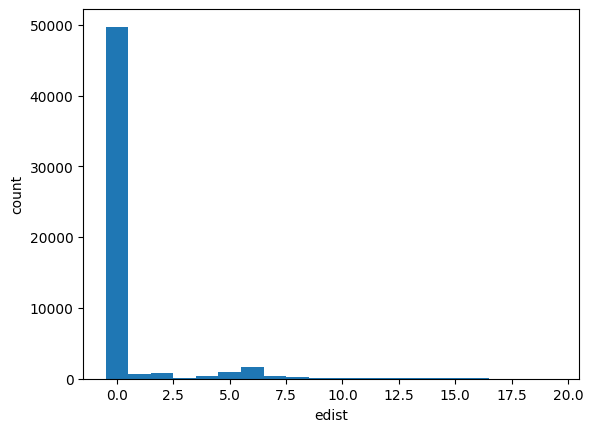

In [98]:
# Most barcodes are perfect match, the mmseqs alignment process only added info to a few cells
# (with edist > 0)
plt.hist(adata.obs['edist_pacbio'], bins=np.arange(-0.5, 20.5, 1))
plt.xlabel('edist')
plt.ylabel('count')

Text(0, 0.5, 'count')

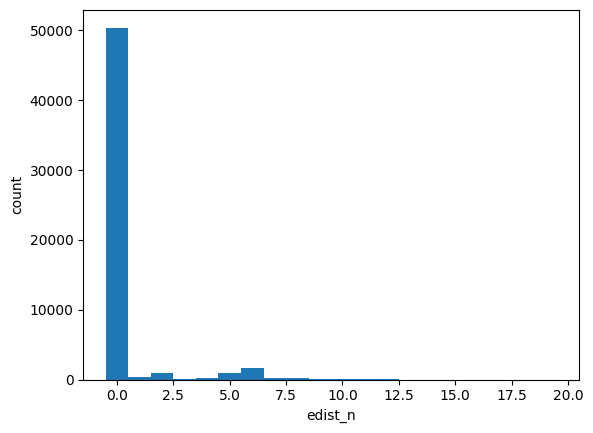

In [99]:
plt.hist(adata.obs['edist_n_pacbio'], bins=np.arange(-0.5, 20.5, 1))
plt.xlabel('edist_n')
plt.ylabel('count')

In [100]:
# This filter allows 2 mismatches (edist_n) and up to 4 N's
f = (~pd.isna(adata.obs['edist_pacbio'])) & (adata.obs['edist_pacbio'] <= 5)
#f1 = (f) & (adata.obs['edist_pacbio'] <= 6)
#f2 = (f) & (adata.obs['edist_n_pacbio'] <= 4)
#print(sum(f1), sum(f2), sum(f1 & f2))
#adata.obs.loc[~(f1 & f2),'variant_pacbio'] = 'None'
print(sum(~f))
adata.obs.loc[~f,'variant_pacbio'] = 'None'
print(sum(adata.obs['variant_pacbio'] == 'None'), sum(adata.obs['variant_pacbio'] != 'None'))

48276
48276 52627


In [101]:
# There are a few cells that get mapped to positional variant with pacbio map but where cellranger assigned to non-positional spike-in. 
# Need to look at these and decide what to do. Should be small number.
# in this case the edists are all small, I will keep the pacbio calls
f2 = (adata.obs['variant_pacbio'] != 'None') & (adata.obs['variant_cr']).isin(nonPositionalSpikeIns)
adata.obs.loc[f2, ['variant_cr', 'variant_pacbio', 'edist_pacbio', 'edist_n_pacbio']]

,variant_cr,variant_pacbio,edist_pacbio,edist_n_pacbio
ACTACCTTCGATTGGC-1-0,mSTING_WT,L59N,2.0,2.0
CAACACGCATAGAGTC-1-0,mSTING_WT,P252V,2.0,2.0
CCTATGTTCCTGGTCC-1-0,mSTING_WT,P252V,2.0,2.0
GGTTCAATCCCTGGCT-1-0,mSTING_WT,Q109Y,4.0,4.0
GTTAGATTCTAATGCG-1-0,mSTING_WT,L363Y,2.0,2.0
GTCAATGTCTGTCAAG-1-1,STOP,S161F,2.0,2.0
TATCCGTTCCCATATC-1-1,mSTING_WT,S161F,2.0,2.0
TCATCAAGTATGTGAG-1-1,STOP,S161F,2.0,2.0
TCTGTGTTCGATATAC-1-1,mSTING_WT,S161F,2.0,2.0
CATATAGCAAGCCAGC-1-2,mSTING_WT,N241V,2.0,2.0


In [102]:
adata.obs['variant'] = adata.obs['variant_pacbio'].copy()
f = (adata.obs['variant'] == 'None') & (adata.obs['variant_cr'] != 'None')
f2 = (f) & (adata.obs['variant_cr'].isin(nonPositionalSpikeIns))
print(f'{sum(f)} cells do not have pacbio variant but do have call from cellranger, {sum(f2)} are non-positional spike-ins. Using cellranger calls for these cells')
adata.obs.loc[f,'variant'] = adata.obs.loc[f,'variant_cr'].copy()
adata.obs.loc[f,'variant_cr'].value_counts().iloc[:10]

18176 cells do not have pacbio variant but do have call from cellranger, 8839 are non-positional spike-ins. Using cellranger calls for these cells


variant_cr
mSTING_WT    5369
STOP         3331
S240X         247
L26X          157
L373X         147
L197X         147
L56X          143
A97X          140
A232X         132
P92X          120
Name: count, dtype: int64

In [103]:
adata.obs['variant'].value_counts()

variant
None         30100
mSTING_WT     5369
STOP          3331
C91A           836
G79V           555
             ...  
S18G             1
P252Q            1
R374G            1
P351I            1
L356P            1
Name: count, Length: 3792, dtype: int64

In [104]:
adata.obs['variant'].value_counts(normalize=True)

variant
None         0.298306
mSTING_WT    0.053210
STOP         0.033012
C91A         0.008285
G79V         0.005500
               ...   
S18G         0.000010
P252Q        0.000010
R374G        0.000010
P351I        0.000010
L356P        0.000010
Name: proportion, Length: 3792, dtype: float64

In [105]:
# given aa mut, return same value but with new AA replaced with X.
# if double mutation replace both
# if special mutation leave as is
def get_aamut_pos_str(aa_mut):
    if ',' in aa_mut:
        tmp = aa_mut.split(',')
        retval = []
        for t in tmp:
            retval.append(get_aamut_pos_str(t))
        return ','.join(retval)
    if aa_mut in list(twist['name']):
        return aa_mut
    tmp = aa_mut[:-1]+'X'
    if tmp not in list(twist['name']) and '_379' not in tmp:
        print(f'error {aa_mut}')
        return None
    return tmp 

In [106]:
adata.obs['variant_pos'] = 'None'
f = adata.obs['variant'] != 'None'
adata.obs.loc[f,'variant_pos'] = [get_aamut_pos_str(x) for x in adata.obs.loc[f,'variant']]

In [107]:
adata

AnnData object with n_obs × n_vars = 100903 × 32245
    obs: 'sample', 'library_size', 'mt_frac', 'totReads', 'numVariant', 'maxvariant', 'variant_tied', 'entropy', 'numvariant_umis', 'numvariant_reads', 'variant_cr', 'consensus_barcode', 'consensus_barcode_twist', 'variant_pacbio', 'twist_mut_pacbio', 'twist_closest_dist_pacbio', 'corrected_barcode_pacbio', 'edist_pacbio', 'edist_n_pacbio', 'variant', 'variant_pos'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'variants', 'log1p'
    obsm: 'variant_counts', 'variant_reads'
    layers: 'read_matrix', 'X_orig', 'X', 'logX'

In [108]:
adata.obs['variant_full'] = adata.obs['variant'].copy()
adata.obs['variant'] = adata.obs['variant_pos'].copy()

In [109]:
f = adata.obs['variant_full'] != 'None'
adata.obs['variant'] = adata.obs['variant'].astype(str)
adata.obs.loc[f,'variant'] = [get_aamut_pos_str(x) for x in adata.obs.loc[f,'variant_full']]

In [110]:
f = pd.isna(adata.obs['corrected_barcode_pacbio'])
adata.obs.loc[f,'corrected_barcode_pacbio'] = adata.obs.loc[f,'consensus_barcode'].copy()

## Combine similar clonal barcodes within variant groups

To get clonal groups, want to combine cells with very close clonal barcode and same AA mutation

These were ultimately not used in satseq paper, but can distinguish whether cells with same observed mutation came from same clonal group

In [111]:
# within all cells with the same variant call, enumerate all observed barcodes
# get distance between all pairs. Do not count columns where either barcode has an N when computing distance.
# if distance is less than 10%, merge less common barcode with more common barcode
# repeat until no merges occur
def combine_clones(variant, varcol='variant_full', verbose=False, maxround=20):
    fbc = (adata.obs[varcol] == variant) & (adata.obs['corrected_barcode_pacbio'] != '')
    if (verbose):
        print(f'number of cells: {sum(fbc)}')
    if variant == 'None' or variant=='':
        return (variant, 0, 0, adata.obs.loc[fbc,'corrected_barcode_pacbio'].copy())
    numround=0
    newbc = adata.obs.loc[fbc, 'corrected_barcode_pacbio'].copy()
    if (verbose):
        print(f'newbc.shape={newbc.shape}')
    total_numfix=0
    while True:
        if verbose:
            print(f'Round {numround}')
        origbc = newbc.copy()
        bcs = origbc.astype(str).value_counts()
        bcmat = pd.DataFrame(1.0, index=[str(x) for x in bcs.index], columns=[str(x) for x in bcs.index])
        if verbose:
            print(f'bcmat.shape={bcmat.shape}')
        for spos, bc1 in enumerate(bcs.index[:-1]):
            for bc2 in bcs.index[spos:]:
                bcmat.loc[bc1,bc2] = barcode_distance(bc1, bc2)/len(bc1)
        numfix=0
        cutoff = 0.1
        for i in bcmat.index:
            f = (bcmat.loc[i] > 0) & (bcmat.loc[i] < cutoff)
            if sum(f) == 0:
                continue
            for j in bcmat.index[f]:
                f2 = origbc == j
                if sum(f2) > 0:
                    newbc[f2] = i
                    if verbose:
                        print(f'combining variant {i} {j} dist={bcmat.loc[i,j]*len(bc1)}')
                    numfix=numfix+1
        total_numfix += numfix
        numround=numround+1
        if numfix == 0:
            break
        if numround > maxround:
            break
    if verbose:
        print(f'Done numfix={total_numfix} numround={numround}')
    return (variant,total_numfix,numround,newbc)

In [112]:
adata.obs['variant_full'].astype(str).value_counts()

variant_full
None         30100
mSTING_WT     5369
STOP          3331
C91A           836
G79V           555
             ...  
S18G             1
P252Q            1
R374G            1
P351I            1
L356P            1
Name: count, Length: 3792, dtype: int64

In [113]:
results = []
adata.obs['clonal_barcode'] = adata.obs['corrected_barcode_pacbio'].astype(str).copy()
with multiprocessing.Pool(processes=50) as p:
    for tmp in  p.imap_unordered(combine_clones, adata.obs['variant_full'].unique()):
        f = (adata.obs['variant_full'] == tmp[0]) & (adata.obs['consensus_barcode'] != '')
        adata.obs.loc[f,'clonal_barcode'] = tmp[3]
        if tmp[1] > 1:
            print(f'{tmp[0]} numfix={tmp[1]} numround={tmp[2]}')

A141X numfix=5 numround=3
R305X numfix=3 numround=2
Y104X numfix=11 numround=3
L66X numfix=7 numround=2
I246X numfix=7 numround=3
I234X numfix=17 numround=4
R17X numfix=24 numround=3
L116X numfix=40 numround=5
A344X numfix=3 numround=3
I311X numfix=83 numround=6
L329X numfix=4 numround=2
S304X numfix=9 numround=2
V73X numfix=4 numround=2
L224X numfix=165 numround=5
H54X numfix=62 numround=4
T341X numfix=47 numround=5
Y106X numfix=205 numround=6
L363X numfix=100 numround=6
L371X numfix=228 numround=7
L101X numfix=69 numround=5
D368X numfix=245 numround=6
P263X numfix=3 numround=2
I114X numfix=61 numround=5
S80X numfix=13 numround=3
M98X numfix=49 numround=4
S117X numfix=48 numround=3
G193X numfix=12 numround=3
S190X numfix=5 numround=2
L63X numfix=68 numround=4
R231X numfix=134 numround=6
Y162X numfix=122 numround=5
K337X numfix=6 numround=3
Q358X numfix=153 numround=5
Y260X numfix=3 numround=3
A192X numfix=134 numround=5
I99X numfix=91 numround=5
E339X numfix=44 numround=4
S242X numfix

In [114]:
adata.obs[['corrected_barcode_pacbio','variant_pacbio']].value_counts().iloc[:20]

corrected_barcode_pacbio              variant_pacbio
                                      None              11694
GTTTATACCTTAGGTACGCTATGTGATGCTAGAGAG  C91A                806
ACCGACATCTTAGTGCAGAACGAGGAATTAGCAACG  None                728
TCTGATGCTCATCACACGCTATTCAGACCGTCATAG  G79V                538
AACGCGGAACCAGCATCGCTCACACGTTGGGAGCTT  L56K                514
TCTATCATGGGAGTCACGCTGGGAGGGTCTTGAATG  E68H                486
NNNNNNNNNNNNNNNNCGCTNNNNNNNNNNNNNNNN  None                420
CTGTTTTAATTTTAGCCGCTCGTCATGGAACTTTAG  R283A               350
CGAACTGCTAGTACTTCGCTCGCCAAGATACTAAGC  L197M               319
TTGCGGTCAGTGTGGTAGAAGTAATGAATACCGAGG  None                309
CATAGTCGTTCACTGTAGAACTGTCTTCGAAGACCA  None                308
TTTTGCCACGCTAGTCCGCTGTAAGGGTAGGTATGT  S102P               298
TATTTACGCTACTGTACGCTGCCAGGATAGGTCTAC  S53C                285
TACTTTCGGGTACGCTCGCTTGGTCAGTCTGTCGGT  A232F               281
TTATTTGTCACTAAGGCGCTATCTTATGGGAGTGTG  S117L               281
AGCATAGAAGGCGCACC

extracting highly variable genes


/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to r

    finished (0:00:11)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:508: FutureWarning: The provided callable <function nanmean at 0x7f1dc0309f30> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  df = df.groupby("gene").agg(
/usr/local/lib/python3.10/dist-packages/scanpy/preprocessing/_highly_variable_genes.py:508: FutureWarning: The provided callable <function nanmean at 0x7f1dc0309f30> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided

Found 4223 highly variable genes


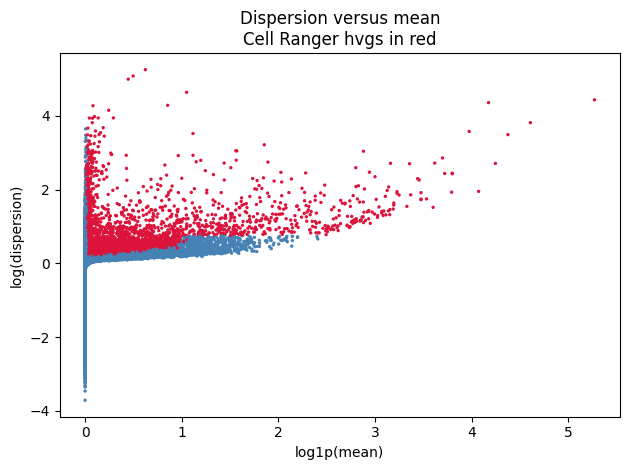

In [115]:
boolean_to_color = {True:'crimson',False:'steelblue'}
sc.settings.verbosity=4
adata.var.drop(columns=['highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatch', 'highly_variable_intersection'],
              inplace=True, errors='ignore')
sc.pp.highly_variable_genes(adata, flavor='cell_ranger', batch_key='sample', n_bins=20, max_mean=np.inf, layer='X')

colors_cell_ranger = [boolean_to_color[True] if x >0 else boolean_to_color[False]
                      for x in adata.var['highly_variable']]
plt.scatter(np.log1p(adata.var['means']), np.log(adata.var['dispersions']),
            s=2, c=colors_cell_ranger)
plt.xlabel('log1p(mean)')
plt.ylabel('log(dispersion)')
plt.title('Dispersion versus mean\nCell Ranger hvgs in red')
print(f'Found {sum(adata.var["highly_variable"])} highly variable genes')
fn = f'{output_dir}/{celltype}_{condition}_hvgs_scanpy_cellranger_20bins_nomax.png'
plt.tight_layout()
plt.savefig(fn, dpi=400)
plt.show()
plt.close()

In [116]:
adata.X = adata.layers['logX']
sc.tl.pca(adata)

computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:52)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PC1', 'PC2', ..., the loadings (adata.var)
    'pca_variance', the variance / eigenvalues (adata.uns)
    'pca_variance_ratio', the variance ratio (adata.uns)


In [117]:
np.max(adata.X)

4.425505

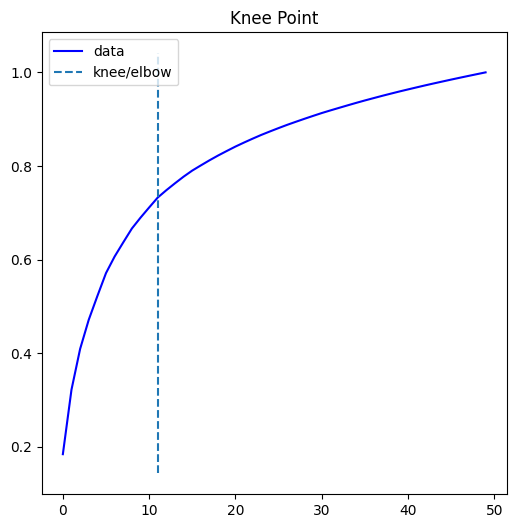

In [118]:
x = range(len(adata.uns['pca']['variance']))
y = np.cumsum(adata.uns['pca']['variance'])
y = y/np.max(y)
kneedle = KneeLocator(x, y)
kneedle.plot_knee()

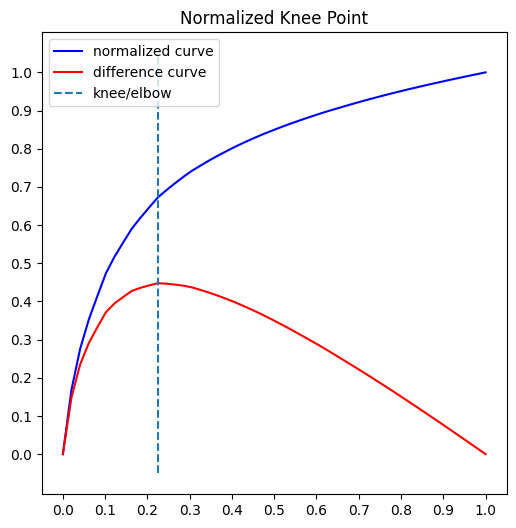

In [119]:
kneedle.plot_knee_normalized()

In [120]:
kneedle.knee

11

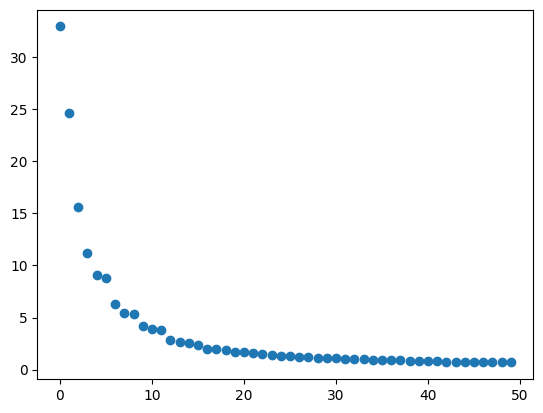

In [121]:
plt.scatter(range(50), adata.uns['pca']['variance'])

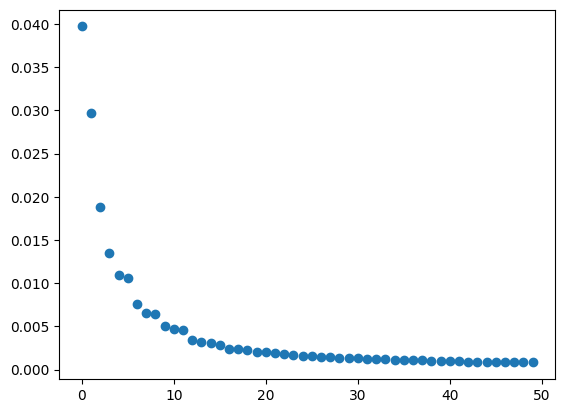

In [122]:
plt.scatter(range(50), adata.uns['pca']['variance_ratio'])

In [123]:
sc.pp.pca(adata, n_comps=kneedle.knee)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

computing PCA
    on highly variable genes
    with n_comps=11
    finished (0:00:15)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PC1', 'PC2', ..., the loadings (adata.var)
    'pca_variance', the variance / eigenvalues (adata.uns)
    'pca_variance_ratio', the variance ratio (adata.uns)
computing neighbors
    computing neighbors
    using 'X_pca' with n_pcs = 11


/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    computed neighbors (0:00:25)
    computed connectivities (0:00:07)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:32)
computing UMAP


  2%|██▊                                                                                                                                                                                          | 3/200 [00:00<00:55,  3.56it/s]

	completed  0  /  200 epochs


 11%|████████████████████▋                                                                                                                                                                       | 22/200 [00:05<00:46,  3.81it/s]

... (15 outputs left out)

 91%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏                | 182/200 [00:47<00:04,  3.82it/s]

	completed  180  /  200 epochs


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:52<00:00,  3.80it/s]

    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:58)


In [124]:
adata.obs['haveVariant'] = pd.Categorical(adata.obs['variant'] != 'None')
adata.obs['haveVariant'].value_counts()

haveVariant
True     70803
False    30100
Name: count, dtype: int64

/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/usr/local/lib/python3.10/dist-packages/scanpy/plotting

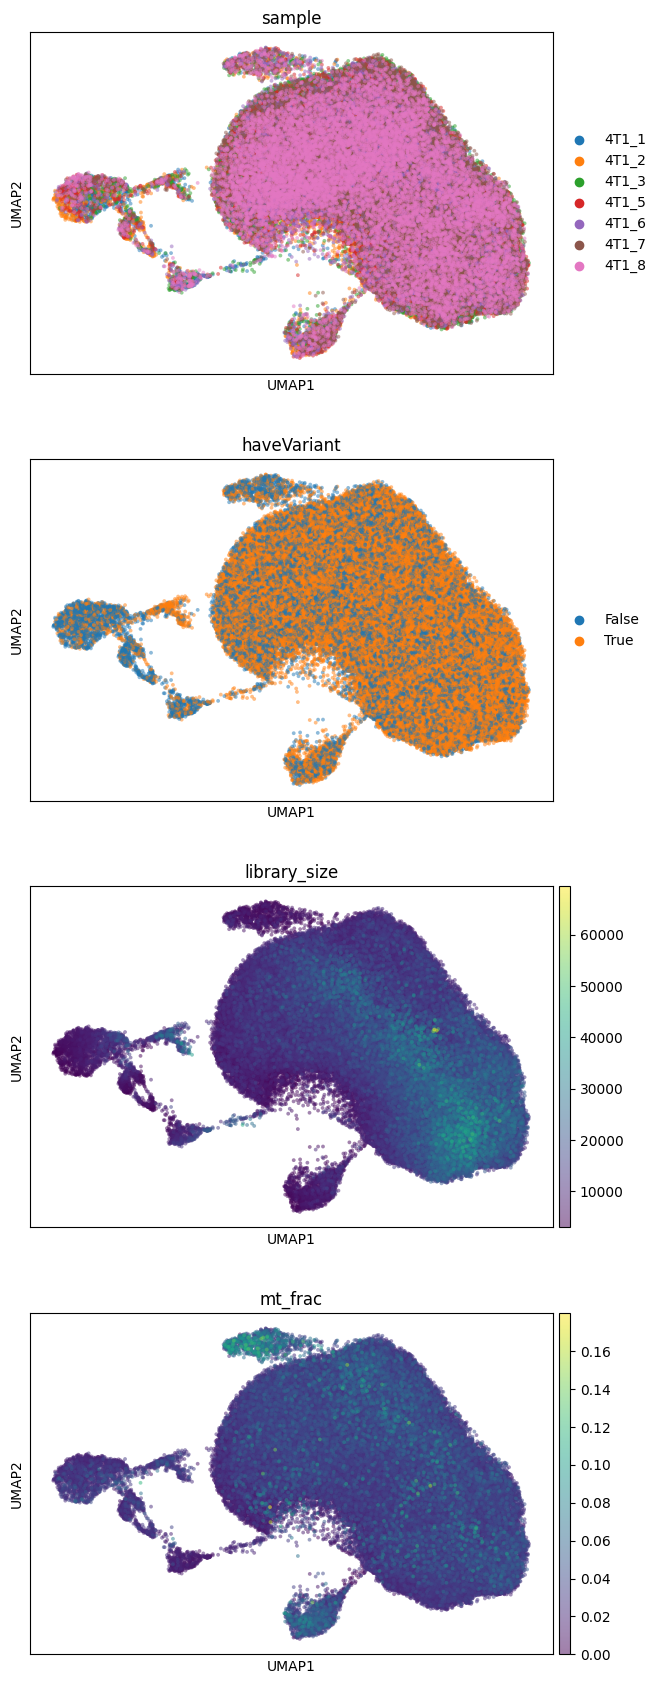

In [125]:
sc.pl.umap(adata, color=['sample', 'haveVariant', 'library_size', 'mt_frac'], ncols=1, s=30, alpha=0.5)

In [126]:
adata.obs['variant'].value_counts().iloc[:20]

variant
None         30100
mSTING_WT     5369
STOP          3331
L56X          1121
C91X          1041
L26X           921
A232X          918
L373X          816
L30X           800
K45X           782
S102X          719
V21X           685
G250X          657
M31X           657
L47X           651
P92X           631
A84X           629
A97X           625
V27X           596
G79X           594
Name: count, dtype: int64

/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/usr/local/lib/python3.10/dist-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/usr/local/lib/python3.10/dist-packages/scanpy/plotting

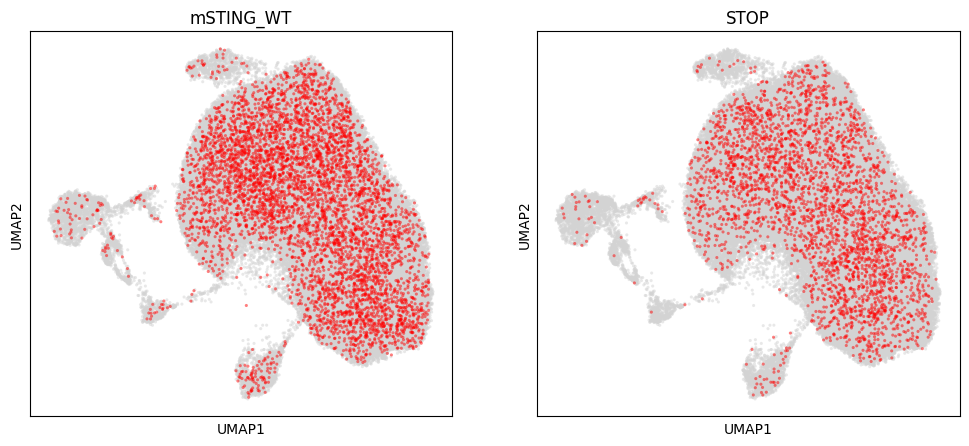

In [127]:
plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
for i, variant in enumerate(['mSTING_WT', 'STOP']):
    f = adata.obs['variant'] == variant
    ax = plt.subplot(1, 2, i+1)
    adata.obs['tmp'] = pd.Categorical(f, categories=[True, False])
    adata.uns['tmp_colors'] = ['red', 'lightgray']
    sc.pl.umap(adata[~f], color='tmp', ax=ax, title=variant, legend_loc=None, show=False, s=20, alpha=0.5)
    f = adata.obs['tmp'] == True
    sc.pl.umap(adata[f], color='tmp', ax=ax, title=variant, legend_loc=None, show=False, s=20, alpha=0.5)
plt.show()

In [128]:
## save to file
adata.write(f'{output_dir}/adata_{celltype}_{condition}.h5ad')